# M2 · Time-series preparation and baselines (Review 2, Method 1)

**Project:** Early warning for severe air-pollution days in Delhi-NCR (Team 11, 23CSE452 Business Analytics)
**Owner:** M2 · **Method 1:** Time-series analysis · **Rubric line covered:** *Method 1: Data preparation and implementation (2 marks)*, plus M2's evidence for *Presentation and individual contribution*.

### What M2 was asked to do, and where it is done here

| # | Task (from the Review 2 work split) | Section | Output |
|---|---|---|---|
| 1 | Build the series file from `pm25_target`, with `target_source` and a missing flag. Gap-fill **features only** (past values, at most 2 days), **never the target** | §1 | `p2_series.csv`, `p2_ts_inputs.csv`, figure `M2_01` |
| 2 | Check the series for consistency across years: do the `pm25_mean`-based lags in `m4_full_engineered.csv` match the label? | §2 | `p2_consistency_by_year.csv`, `p2_phase1_feature_audit.csv`, figures `M2_02`–`M2_04` |
| 3 | Exploration: yearly and weekly patterns, STL decomposition, stationarity test, ACF and PACF, log-transform check | §3 | figures `M2_05`–`M2_10`, `p2_stationarity_tests.csv` |
| 4 | Baselines for days 1, 2 and 3: persistence and seasonal naive (plus a day-of-year average as a fairer seasonal benchmark) | §4 | `p2_baselines.csv`, `p2_baseline_metrics.csv`, `p2_baseline_backtest.csv`, figures `M2_11`–`M2_13` |
| – | Hand-off to M3 (models), M4 (rules), M5 (dashboard), M1 (report) | §5–6 | contract check + notes |

### Frozen team settings used here (same as Phase 1)
* **Series:** `pm25_target` — the reference station, or the city mean on days the reference is missing and ≥ 10 stations reported. Never `pm25_mean`.
* **Alert cut-off:** `pm25_target ≥ 120.5 µg/m³` (PM2.5-based AQI above 300, CPCB "Very Poor" or worse) → `high_risk = 1`.
* **Split:** train 2018-01-01 → 2024-12-31, test 2025-01-01 → 2026-09-30.
* **Horizons:** 1, 2 and 3 days ahead. A forecast is made at the end of day *t* (the origin) for day *t + h*, using only data up to day *t*.

**Rule for every statistic fitted in this notebook** (Box-Cox λ, Fourier seasonality, stationarity tests, ACF/PACF, the day-of-year average): it uses **training years only**, so nothing from 2025–2026 leaks into choices M3 builds on.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.metrics import roc_auc_score
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning

warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.width", 160, "display.max_columns", 40, "display.max_colwidth", 140)

# ---- Frozen team settings ----
THRESH      = 120.5                       # AQI 301 starts at PM2.5 >= 120.5 (CPCB, after rounding)
SEVERE      = 250.5                       # AQI 401+ starts at PM2.5 >= 250.5
PM          = "pm25_target"               # the series behind high_risk
TRAIN_START = pd.Timestamp("2018-01-01")
TRAIN_END   = pd.Timestamp("2024-12-31")
TEST_START  = pd.Timestamp("2025-01-01")
TEST_END    = pd.Timestamp("2026-09-30")
HORIZONS    = [1, 2, 3]
FFILL_LIMIT = 2                           # features may reuse a past value at most 2 days old
WINTER      = [11, 12, 1]                 # Phase 1 EDA definition of winter (Nov-Jan)
SEASON      = [10, 11, 12, 1, 2]          # pollution season (Oct-Feb), as used for M4's winter rule mining
CLIM_WINDOW = 15                          # day-of-year average: centred, circular 15-day window
BLOCK       = 14                          # block length (days) for the moving-block bootstrap
N_BOOT      = 1000
SEED        = 42
rng = np.random.default_rng(SEED)

# ---- Paths ----
def find(name, required=True):
    for p in [Path(name), Path("data") / name, Path("m4") / name, Path("..") / name, Path("../data") / name]:
        if p.exists():
            return p
    if required:
        raise FileNotFoundError(f"{name} not found in ., data/, m4/ or ../")
    return None

FIG = Path("figures_m2"); FIG.mkdir(exist_ok=True)
OUT = Path(".")

# ---- Chart style (same palette as the M3 EDA and M4 notebooks) ----
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
BASE_COL = {"persistence": BLUE, "seasonal_naive": ORANGE, "climatology": AQUA}
BASE_LBL = {"persistence": "Persistence", "seasonal_naive": "Seasonal naive (same date last year)",
            "climatology": "Day-of-year average (2018-2024)"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10.5, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9.5, "figure.dpi": 110, "lines.linewidth": 1.6,
})
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
MNAME = dict(zip(range(1, 13), MONTHS))

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

def year_axis(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

print("Settings frozen. Figures ->", FIG.resolve())

Settings frozen. Figures -> /home/claude/m2_review2/figures_m2


## 0. Load the inputs and verify the target

Main input: `m4_full_engineered.csv` (Phase 1 feature-engineering output, 3,195 days). As an independent check, `pm25_target` is **rebuilt from the cleaned merged file** using the documented rule (reference station, else city mean with ≥ 10 stations) and must match exactly. If the M4 file is ever missing, the notebook falls back to the rebuilt series.

In [2]:
def rebuild_target(merged):
    # Documented Phase 1 rule: reference station, else city mean when >= 10 stations reported, else missing.
    ref, city, n = merged["pm25_ref_station"], merged["pm25_mean"], merged["pm25_n_stations"]
    src = np.select([ref.notna(), city.notna() & (n >= 10)], ["reference", "city_fallback"], default="missing")
    tgt = np.where(src == "reference", ref, np.where(src == "city_fallback", city, np.nan))
    return pd.Series(tgt, index=merged.index), pd.Series(src, index=merged.index)

m4_path     = find("m4_full_engineered.csv", required=False)
merged_path = find("merged_daily_cleaned dataset.csv", required=False) or find("merged_daily_clean_m2.csv", required=False)

if merged_path is not None:
    merged = pd.read_csv(merged_path, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
    merged["pm25_target_rebuilt"], merged["target_source_rebuilt"] = rebuild_target(merged)
    print(f"Merged file : {merged_path}  {merged.shape}")

if m4_path is not None:
    df = pd.read_csv(m4_path, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
    print(f"M4 file     : {m4_path}  {df.shape}")
    if merged_path is not None:
        assert len(df) == len(merged) and (df.date.values == merged.date.values).all()
        assert np.allclose(df[PM], merged.pm25_target_rebuilt, equal_nan=True), "pm25_target differs from the documented rule"
        assert (df.target_source == merged.target_source_rebuilt).all(), "target_source differs from the documented rule"
        print("Check passed: pm25_target and target_source rebuilt from the merged file match M4 exactly.")
else:
    print("M4 file not found -> using the target rebuilt from the merged file.")
    df = merged.copy()
    df[PM], df["target_source"] = df.pm25_target_rebuilt, df.target_source_rebuilt
    df["high_risk"] = np.where(df[PM].notna(), (df[PM] >= THRESH).astype(float), np.nan)
df = df.copy()

# Structural checks
gaps = df.date.diff().dropna()
assert (gaps == pd.Timedelta("1D")).all(), "dates are not one continuous daily index"
assert df.date.min() == TRAIN_START and df.date.max() == TEST_END
known = df[PM].notna()
assert ((df.loc[known, PM] >= THRESH).astype(float) == df.loc[known, "high_risk"]).all()
assert df.loc[~known, "high_risk"].isna().all()
assert (df.loc[known, PM] > 0).all()

n_days, n_known = len(df), int(known.sum())
print(f"\n{n_days} consecutive days, {df.date.min().date()} -> {df.date.max().date()}")
print(f"Target present on {n_known} days, missing on {n_days - n_known} ({100*(n_days-n_known)/n_days:.1f}%)")
print(f"high_risk = 1 on {int(df.high_risk.sum())} of {n_known} days ({100*df.high_risk.mean():.1f}%)")
display(df.target_source.value_counts().rename("days").to_frame())

Merged file : data/merged_daily_cleaned dataset.csv  (3195, 29)
M4 file     : data/m4_full_engineered.csv  (3195, 118)
Check passed: pm25_target and target_source rebuilt from the merged file match M4 exactly.

3195 consecutive days, 2018-01-01 -> 2026-09-30
Target present on 2923 days, missing on 272 (8.5%)
high_risk = 1 on 792 of 2923 days (27.1%)


,days
target_source,
reference,2836
missing,272
city_fallback,87


## 1. Task 1 — Build the series file

Two files:

* **`p2_series.csv`** — exactly the agreed contract: `date, pm25_target, target_source, missing, high_risk`. All 3,195 days, target **never filled** (missing days stay empty).
* **`p2_ts_inputs.csv`** — what forecasting models read *as inputs*. `pm25_input` is the target carried forward from the most recent observed day, **at most 2 days old** and **only from the past**. `input_age_days` says how old it is (0 = observed that day). Lags 1–7 are built from `pm25_input`, i.e. from `pm25_target`, never from `pm25_mean` (see §2 for why). Calendar fields and the Fourier seasonal terms chosen in §3 are added at the end of §3.

Why the 2-day limit: most gaps are one or two days, so a short carry-forward keeps more forecast origins usable without inventing pollution data. Longer gaps stay missing, and the score is always computed only on days with a real observed target.

131 gaps covering 272 days; 112 gaps are 1-2 days long.


gap length (days),1,2,3,4,6,7,9,12,31,32
number of gaps,96,16,8,4,1,2,1,1,1,1
days covered,96,32,24,16,6,14,9,12,31,32


Longest gaps:


,start,end,days
0,2019-02-15,2019-03-18,32
1,2023-02-16,2023-03-18,31
2,2023-02-02,2023-02-13,12
3,2021-07-26,2021-08-03,9
4,2018-02-26,2018-03-04,7



Inputs: 166 of 272 missing days get a carried-forward input (<= 2 days old); 106 days have no usable input.


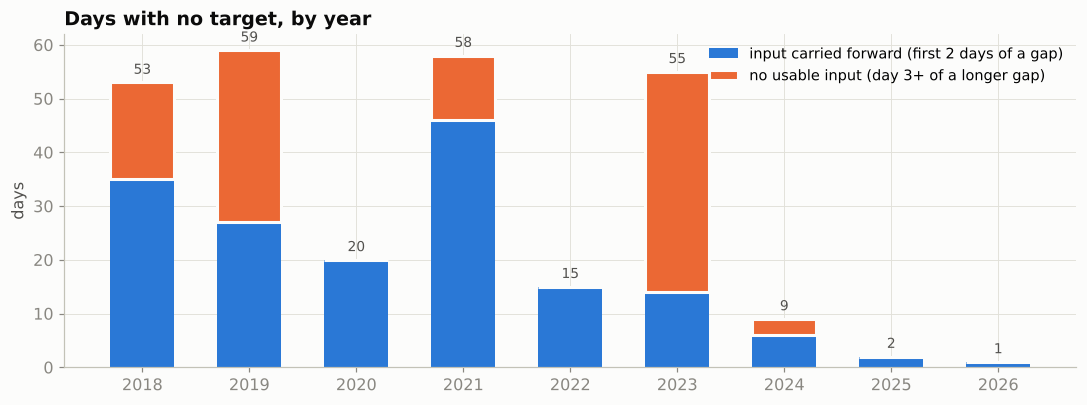

In [3]:
# ---- p2_series.csv (contract) ----
series = df[["date", PM, "target_source", "high_risk"]].copy()
series["missing"] = series[PM].isna().astype(int)
series["high_risk"] = series["high_risk"].astype("Int64")
series = series[["date", PM, "target_source", "missing", "high_risk"]]

# ---- Gap structure ----
miss = series["missing"].astype(bool)
run_id = (miss != miss.shift()).cumsum()
runs = (series.assign(run=run_id)[miss].groupby("run")
        .agg(start=("date", "min"), end=("date", "max"), days=("date", "size")))
gap_table = runs.days.value_counts().sort_index().rename_axis("gap length (days)").rename("number of gaps").to_frame()
gap_table["days covered"] = gap_table.index * gap_table["number of gaps"]
print(f"{len(runs)} gaps covering {int(miss.sum())} days; "
      f"{int((runs.days <= 2).sum())} gaps are 1-2 days long.")
display(gap_table.T)
print("Longest gaps:")
display(runs.sort_values("days", ascending=False).head(5).reset_index(drop=True))

# ---- Inputs: carry the last observed value forward, at most FFILL_LIMIT days, past only ----
inp = series.set_index("date")[PM]
last_obs_date = pd.Series(inp.index.where(inp.notna()), index=inp.index).ffill()
age = (inp.index.to_series() - last_obs_date).dt.days
pm25_input = inp.ffill(limit=FFILL_LIMIT)
age = age.where(pm25_input.notna())

ts = pd.DataFrame({"date": inp.index, PM: inp.values,
                   "pm25_input": pm25_input.values, "input_age_days": age.values})
ts["input_filled"] = (ts.input_age_days > 0).astype(int)
ts["log_pm25"] = np.log(ts[PM])
ts["log_pm25_input"] = np.log(ts["pm25_input"])
for k in range(1, 8):
    ts[f"pm25_input_lag{k}"] = ts["pm25_input"].shift(k)
ts["year"], ts["month"] = ts.date.dt.year, ts.date.dt.month
ts["day_of_week"] = ts.date.dt.dayofweek
ts["period"] = np.where(ts.date <= TRAIN_END, "train", "test")
ts["is_winter_nov_jan"] = ts.month.isin(WINTER).astype(int)
ts["is_season_oct_feb"] = ts.month.isin(SEASON).astype(int)

# ---- Guards: the target is never filled, filling only looks back, never more than 2 days ----
assert ts.loc[ts[PM].notna(), "pm25_input"].equals(ts.loc[ts[PM].notna(), PM])
assert ts.input_age_days.dropna().between(0, FFILL_LIMIT).all()
assert series[PM].isna().sum() == df[PM].isna().sum()
filled = int(ts.input_filled.sum()); still = int(ts.pm25_input.isna().sum())
print(f"\nInputs: {filled} of {int(miss.sum())} missing days get a carried-forward input (<= {FFILL_LIMIT} days old); "
      f"{still} days have no usable input.")

fig, ax = plt.subplots(figsize=(10, 3.8))
by_year = ts.assign(miss=ts[PM].isna()).groupby("year").agg(
    filled=("input_filled", "sum"), unfilled=("pm25_input", lambda s: s.isna().sum()))
ax.bar(by_year.index, by_year.filled, color=BLUE, width=0.6, label=f"input carried forward (first {FFILL_LIMIT} days of a gap)")
ax.bar(by_year.index, by_year.unfilled, bottom=by_year.filled, color=ORANGE, width=0.6,
       label="no usable input (day 3+ of a longer gap)", edgecolor=SURFACE, linewidth=2)
for x, (a, b) in by_year.iterrows():
    ax.text(x, a + b + 1, f"{a + b}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_title("Days with no target, by year"); ax.set_ylabel("days"); ax.set_xticks(by_year.index)
ax.legend(loc="upper right"); fig.tight_layout(); save(fig, "M2_01_missing_days_by_year")

## 2. Task 2 — Is the series consistent across years?

Phase 1 built the label from `pm25_target`, but several Phase 1 features were built from `pm25_mean` (the city mean). Those are only the same series if the city mean is made of the same stations every year. This section checks that, year by year, and then checks every pollution feature Phase 1 gave the model.

target_source,reference,city_fallback,missing,median_stations_in_city_mean,days_with_both,pct_city_mean_equals_target,median_ratio_city_mean_to_target,mean_abs_diff_ugm3,pct_disagree_on_alert
year,,,,,,,,,
2018,287,25,53,1.0,312,54.2,1.000,11.5,6.4
2019,298,8,59,7.0,306,41.8,1.000,5.5,1.6
2020,345,1,20,17.0,346,7.8,1.030,10.4,4.6
2021,306,1,58,1.0,307,48.5,1.000,8.9,3.9
2022,324,26,15,1.0,350,57.4,1.000,6.1,2.9
2023,310,0,55,1.0,310,100.0,1.000,0.0,0.0
2024,357,0,9,1.0,357,100.0,1.000,0.0,0.0
2025,352,11,2,31.0,363,18.2,1.087,8.1,1.7
2026,257,15,1,31.0,272,15.1,1.040,5.4,2.2


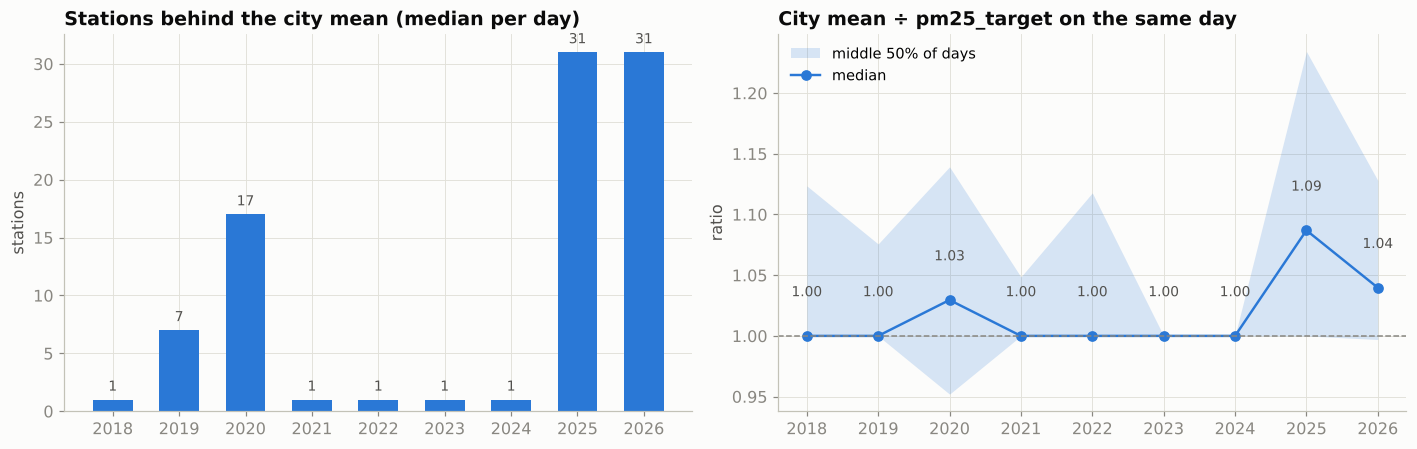

In [4]:
d = df.copy(); d["year"] = d.date.dt.year
both = d[d[PM].notna() & d.pm25_mean.notna()]

src_year = pd.crosstab(d.year, d.target_source)[["reference", "city_fallback", "missing"]]
cons = src_year.copy()
cons["median_stations_in_city_mean"] = d.groupby("year").pm25_n_stations.median()
cons["days_with_both"] = both.groupby("year").size()
cons["pct_city_mean_equals_target"] = (100 * both.assign(eq=np.isclose(both.pm25_mean, both[PM]))
                                       .groupby("year").eq.mean()).round(1)
cons["median_ratio_city_mean_to_target"] = (both.pm25_mean / both[PM]).groupby(both.year).median().round(3)
cons["mean_abs_diff_ugm3"] = (both.pm25_mean - both[PM]).abs().groupby(both.year).mean().round(1)
cons["pct_disagree_on_alert"] = (100 * ((both.pm25_mean >= THRESH) != (both[PM] >= THRESH))
                                 .groupby(both.year).mean()).round(1)
cons.to_csv(OUT / "p2_consistency_by_year.csv")
display(cons)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.bar(cons.index, cons.median_stations_in_city_mean, color=BLUE, width=0.6)
for x, v in cons.median_stations_in_city_mean.items():
    ax.text(x, v + 0.5, f"{v:.0f}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_title("Stations behind the city mean (median per day)"); ax.set_xticks(cons.index); ax.set_ylabel("stations")
ax = axes[1]
r = (both.pm25_mean / both[PM]).groupby(both.year)
q = pd.DataFrame({"q25": r.quantile(.25), "med": r.median(), "q75": r.quantile(.75)})
ax.fill_between(q.index, q.q25, q.q75, color=BLUE, alpha=0.18, lw=0, label="middle 50% of days")
ax.plot(q.index, q.med, color=BLUE, marker="o", ms=6, label="median")
ax.axhline(1, color=MUTED, lw=1, ls="--")
for x, v in q.med.items():
    ax.text(x, v + 0.03, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_title("City mean ÷ pm25_target on the same day"); ax.set_xticks(q.index); ax.set_ylabel("ratio")
ax.legend(loc="upper left")
fig.tight_layout(); save(fig, "M2_02_city_mean_vs_target_by_year")

**Reading the table.** Until 2024 the city mean is usually one station — the same reference station behind the label — so `pm25_mean` and `pm25_target` are often identical. From 2025 the city mean averages about 31 stations and sits a few percent above the reference station. The two series therefore stop being the same thing **exactly at the train/test split**.

Next: which Phase 1 features are built from which series, and do any of them use pollution measured on the day being predicted?

In [5]:
fl_path = find("m4_feature_list.csv", required=False)
if fl_path is not None:
    FEATURES = pd.read_csv(fl_path)["feature"].tolist()
else:  # reproduce M4's selection rule
    EXCLUDE = ["date", "year", "pm25_mean", "pm25_median", "pm25_ref_station", "pm25_n_stations",
               "pm25_n_extreme_flagged", "pm25_target", "aqi_pm25", "high_risk", "aqi_category",
               "high_risk_city", "target_source", "prev_pm25", "next_pm25", "pm10_median",
               "pm10_n_stations", "pm10_n_extreme_flagged", "season"]
    FEATURES = [c for c in df.columns if c not in EXCLUDE]
print(f"Phase 1 model features: {len(FEATURES)}")

# Recompute each pollution feature from its definition (M4 notebook cells 11-23) and record what it is built from
pm, aqi, pm10 = df.pm25_mean, df.aqi_pm25, df.pm10_mean
recipes = {
    "aqi_pm25_lag1":        (aqi.shift(1),                                  "pm25_target (as AQI)", "no"),
    "aqi_pm25_lag2":        (aqi.shift(2),                                  "pm25_target (as AQI)", "no"),
    "aqi_pm25_lag3":        (aqi.shift(3),                                  "pm25_target (as AQI)", "no"),
    "prev_high_risk":       (df.high_risk.shift(1),                         "pm25_target (label)",  "no"),
    "high_risk_past3d":     (df.high_risk.shift(1).rolling(3, min_periods=1).sum(), "pm25_target (label)", "no"),
    "high_risk_past7d":     (df.high_risk.shift(1).rolling(7, min_periods=1).sum(), "pm25_target (label)", "no"),
    "pm25_mean_lag1":       (pm.shift(1),                                   "pm25_mean (city mean)", "no"),
    "pm25_mean_lag2":       (pm.shift(2),                                   "pm25_mean (city mean)", "no"),
    "pm25_mean_lag3":       (pm.shift(3),                                   "pm25_mean (city mean)", "no"),
    "pm25_mean_roll3_mean": (pm.shift(1).rolling(3, min_periods=1).mean(),  "pm25_mean (city mean)", "no"),
    "pm25_mean_roll3_std":  (pm.shift(1).rolling(3, min_periods=1).std(),   "pm25_mean (city mean)", "no"),
    "pm25_mean_roll7_mean": (pm.shift(1).rolling(7, min_periods=1).mean(),  "pm25_mean (city mean)", "no"),
    "pm25_mean_roll7_std":  (pm.shift(1).rolling(7, min_periods=1).std(),   "pm25_mean (city mean)", "no"),
    "pm25_mean_change":     (pm - pm.shift(1),                              "pm25_mean (city mean)", "YES (day t minus day t-1)"),
    "pm10_mean":            (pm10,                                          "pm10_mean",             "YES (day t)"),
    "pm10_mean_lag1":       (pm10.shift(1),                                 "pm10_mean",             "no"),
    "pm10_mean_lag2":       (pm10.shift(2),                                 "pm10_mean",             "no"),
    "pm10_mean_lag3":       (pm10.shift(3),                                 "pm10_mean",             "no"),
    "pm25_pm10_ratio":      (np.where(pm10.notna() & (pm10 > 0), pm / pm10, np.nan), "pm25_mean ÷ pm10_mean", "YES (both day t)"),
    "pm10_available":       (pm10.notna().astype(int),                      "pm10_mean",             "YES (day t)"),
}
test_rows = (df.date >= TEST_START) & df.high_risk.notna()
rows = []
for feat, (rec, base, same_day) in recipes.items():
    rec = pd.Series(rec, index=df.index, dtype=float)
    verified = np.allclose(rec, df[feat].astype(float), equal_nan=True)
    t = df.loc[test_rows, [feat, "high_risk"]].dropna()
    auc = roc_auc_score(t.high_risk, t[feat]) if t[feat].nunique() > 1 else np.nan
    rows.append({"feature": feat, "in_phase1_model": feat in FEATURES, "built_from": base,
                 "uses_pollution_from_day_t": same_day, "recipe_verified": verified,
                 "test_auc_alone": round(max(auc, 1 - auc), 3) if pd.notna(auc) else np.nan, "test_rows": len(t)})
audit = pd.DataFrame(rows)
assert audit.recipe_verified.all(), audit[~audit.recipe_verified]
audit["verdict"] = np.select(
    [audit.uses_pollution_from_day_t.str.startswith("YES"), audit.built_from.str.startswith("pm25_mean")],
    ["LEAK: drop (pollution measured on the day being predicted)", "Inconsistent basis: rebuild from pm25_target"],
    default="OK")
audit.to_csv(OUT / "p2_phase1_feature_audit.csv", index=False)
display(audit)

Phase 1 model features: 99


,feature,in_phase1_model,built_from,uses_pollution_from_day_t,recipe_verified,test_auc_alone,test_rows,verdict
0,aqi_pm25_lag1,True,pm25_target (as AQI),no,True,0.982,613,OK
1,aqi_pm25_lag2,True,pm25_target (as AQI),no,True,0.966,612,OK
2,aqi_pm25_lag3,True,pm25_target (as AQI),no,True,0.958,612,OK
3,prev_high_risk,True,pm25_target (label),no,True,0.920,634,OK
4,high_risk_past3d,True,pm25_target (label),no,True,0.946,635,OK
5,high_risk_past7d,True,pm25_target (label),no,True,0.966,635,OK
6,pm25_mean_lag1,True,pm25_mean (city mean),no,True,0.980,634,Inconsistent basis: rebuild from pm25_target
7,pm25_mean_lag2,True,pm25_mean (city mean),no,True,0.965,633,Inconsistent basis: rebuild from pm25_target
8,pm25_mean_lag3,True,pm25_mean (city mean),no,True,0.958,633,Inconsistent basis: rebuild from pm25_target
9,pm25_mean_roll3_mean,True,pm25_mean (city mean),no,True,0.977,635,Inconsistent basis: rebuild from pm25_target


pm25_mean_lag1 versus the label's own lag (pm25_target lag 1):


,days,% identical to pm25_target lag1,median ratio,mean abs diff (µg/m³),% disagree on >= 120.5
per,,,,,
train (2018-24),2287.0,58.6,1.000,6.0,2.8
test (2025-26),636.0,17.0,1.061,6.9,1.9


pm25_mean_lag1 + pm25_mean_change = today's city mean. On 634 test days it separates high-risk days with AUC 0.998; a plain >= 120.5 rule on it is right on 98.1% of days.

Days where both the reference station and a >= 10-station city mean exist: 1298; median ratio city/reference = 1.088. The 87 fallback days are therefore on a slightly higher level than reference days (small: they are 2.7% of all days).


year,2018,2019,2020,2021,2022,2023,2024,2025,2026
all months with data,33.0,28.1,26.6,35.2,23.7,29.4,28.3,26.4,11.8
Jan-Sep only,20.7,15.7,12.7,22.8,11.8,10.1,17.7,11.1,11.8
Oct-Dec only,65.9,58.4,67.8,65.9,59.8,75.0,59.3,71.7,NaN


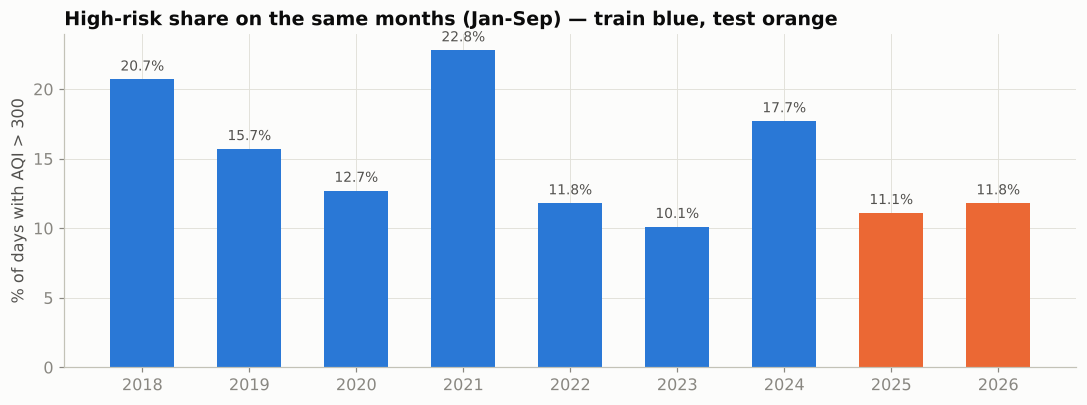

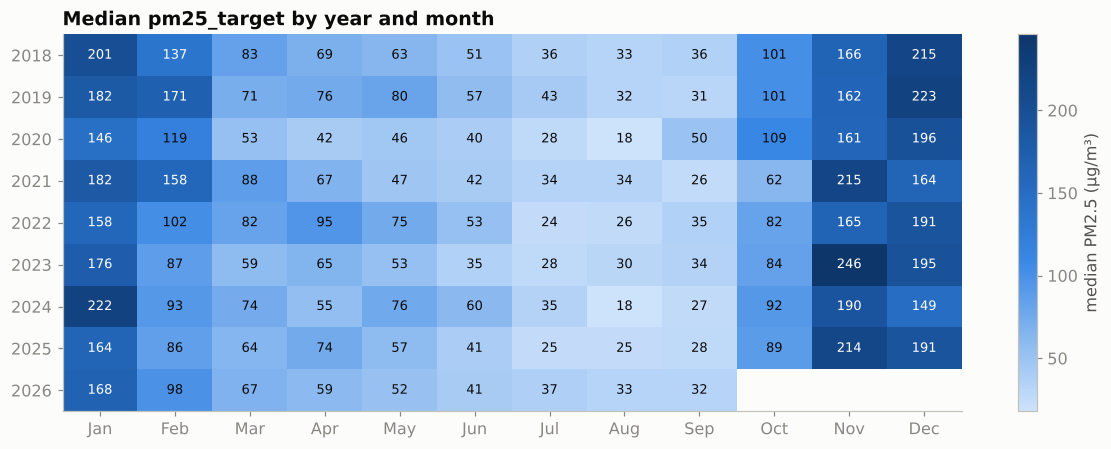

In [6]:
# 1) How far the pm25_mean lag drifts from the label's own lag, train vs test
lag_t = df[PM].shift(1)
x = df.assign(lag_t=lag_t, per=np.where(df.date <= TRAIN_END, "train (2018-24)", "test (2025-26)")).dropna(
    subset=["pm25_mean_lag1", "lag_t"])
drift = x.groupby("per", sort=False).apply(lambda g: pd.Series({
    "days": len(g),
    "% identical to pm25_target lag1": round(100 * np.isclose(g.pm25_mean_lag1, g.lag_t).mean(), 1),
    "median ratio": round((g.pm25_mean_lag1 / g.lag_t).median(), 3),
    "mean abs diff (µg/m³)": round((g.pm25_mean_lag1 - g.lag_t).abs().mean(), 1),
    "% disagree on >= 120.5": round(100 * ((g.pm25_mean_lag1 >= THRESH) != (g.lag_t >= THRESH)).mean(), 1)}))
print("pm25_mean_lag1 versus the label's own lag (pm25_target lag 1):")
display(drift)

# 2) The same-day leak, demonstrated: lag1 + change gives back today's city mean
t = df.loc[test_rows].assign(today=lambda g: g.pm25_mean_lag1 + g.pm25_mean_change).dropna(subset=["today"])
auc_today = roc_auc_score(t.high_risk, t.today)
acc_today = ((t.today >= THRESH) == t.high_risk).mean()
print(f"pm25_mean_lag1 + pm25_mean_change = today's city mean. On {len(t)} test days it separates high-risk "
      f"days with AUC {auc_today:.3f}; a plain >= {THRESH} rule on it is right on {100*acc_today:.1f}% of days.")

# 3) Fallback days: is the >= 10-station city mean on the same level as the reference station?
ov = df[df.pm25_ref_station.notna() & df.pm25_mean.notna() & (df.pm25_n_stations >= 10)]
print(f"\nDays where both the reference station and a >= 10-station city mean exist: {len(ov)}; "
      f"median ratio city/reference = {(ov.pm25_mean / ov.pm25_ref_station).median():.3f}. "
      f"The {int((df.target_source == 'city_fallback').sum())} fallback days are therefore on a slightly higher level "
      f"than reference days (small: they are {100*(df.target_source=='city_fallback').mean():.1f}% of all days).")

# 4) Like-for-like yearly high-risk share (2026 only runs Jan-Sep)
jan_sep = d[d.month <= 9].groupby("year").high_risk.mean().mul(100).round(1)
full = d.groupby("year").high_risk.mean().mul(100).round(1)
oct_dec = d[d.month >= 10].groupby("year").high_risk.mean().mul(100).round(1)
like = pd.DataFrame({"all months with data": full, "Jan-Sep only": jan_sep, "Oct-Dec only": oct_dec})
display(like.T)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(like.index, like["Jan-Sep only"], color=[BLUE if y <= 2024 else ORANGE for y in like.index], width=0.6)
for xv, v in like["Jan-Sep only"].items():
    ax.text(xv, v + 0.4, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_title("High-risk share on the same months (Jan-Sep) — train blue, test orange")
ax.set_ylabel("% of days with AQI > 300"); ax.set_xticks(like.index)
fig.tight_layout(); save(fig, "M2_03_high_risk_share_like_for_like")

# 5) Monthly median of the target by year: does the level stay stable?
hm = d.pivot_table(index="year", columns="month", values=PM, aggfunc="median")
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(hm.values, cmap=SEQ, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index); ax.grid(False)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="white" if v > 120 else INK)
fig.colorbar(im, ax=ax, label="median PM2.5 (µg/m³)")
ax.set_title("Median pm25_target by year and month")
fig.tight_layout(); save(fig, "M2_04_monthly_median_by_year")

In [7]:
n_leak = int(audit.verdict.str.startswith("LEAK").sum())
n_incons = int(audit.verdict.str.startswith("Inconsistent").sum())
tr_eq = drift.iloc[0]["% identical to pm25_target lag1"]; te_eq = drift.iloc[1]["% identical to pm25_target lag1"]
tr_r, te_r = drift.iloc[0]["median ratio"], drift.iloc[1]["median ratio"]
print("CONCLUSIONS OF THE CONSISTENCY CHECK")
print(f"1. The label series is consistent: {100*(df.target_source=='reference').mean():.1f}% of days come from one reference "
      f"station, the {int((df.target_source=='city_fallback').sum())} fallback days are few, and the monthly medians in the "
      f"heat map stay in the same range every year (no level break at 2025).")
print(f"2. The city mean is NOT consistent: one station before 2025, ~31 from 2025. pm25_mean_lag1 equals the label's own "
      f"lag on {tr_eq}% of training days but only {te_eq}% of test days (median ratio {tr_r} -> {te_r}).")
print(f"   {n_incons} Phase 1 features are built from pm25_mean. The effect on the yes/no alert is small "
      f"({drift.iloc[0]['% disagree on >= 120.5']}% of training and {drift.iloc[1]['% disagree on >= 120.5']}% of test days "
      f"land on the other side of 120.5), but numeric forecasts shift. Rule for Review 2: build every lag from pm25_target.")
print(f"3. {n_leak} Phase 1 features use pollution measured on the day being predicted (pm25_mean_change, pm10_mean, "
      f"pm25_pm10_ratio, pm10_available). Passed to M3: drop them and re-score Phase 1 before comparing.")
print(f"4. 2026's low high-risk share is a calendar effect: on Jan-Sep only, 2026 = {like.loc[2026,'Jan-Sep only']}% "
      f"versus {like.loc[2018:2024,'Jan-Sep only'].min()}-{like.loc[2018:2024,'Jan-Sep only'].max()}% in 2018-2024.")

CONCLUSIONS OF THE CONSISTENCY CHECK
1. The label series is consistent: 88.8% of days come from one reference station, the 87 fallback days are few, and the monthly medians in the heat map stay in the same range every year (no level break at 2025).
2. The city mean is NOT consistent: one station before 2025, ~31 from 2025. pm25_mean_lag1 equals the label's own lag on 58.6% of training days but only 17.0% of test days (median ratio 1.0 -> 1.061).
   7 Phase 1 features are built from pm25_mean. The effect on the yes/no alert is small (2.8% of training and 1.9% of test days land on the other side of 120.5), but numeric forecasts shift. Rule for Review 2: build every lag from pm25_target.
3. 4 Phase 1 features use pollution measured on the day being predicted (pm25_mean_change, pm10_mean, pm25_pm10_ratio, pm10_available). Passed to M3: drop them and re-score Phase 1 before comparing.
4. 2026's low high-risk share is a calendar effect: on Jan-Sep only, 2026 = 11.8% versus 10.1-22.8% in 2018

## 3. Task 3 — Exploration

Descriptive charts show the whole series (test period shaded). Every statistic that informs a modelling choice is computed on **2018–2024 only**.

STL, ADF/KPSS and ACF/PACF cannot take gaps, so they run on a copy of the log series with gaps **linearly interpolated for this analysis only** (the interpolated values are never written to any output file).

Training days: 2557; 269 interpolated in the analysis copy only (10.5%).


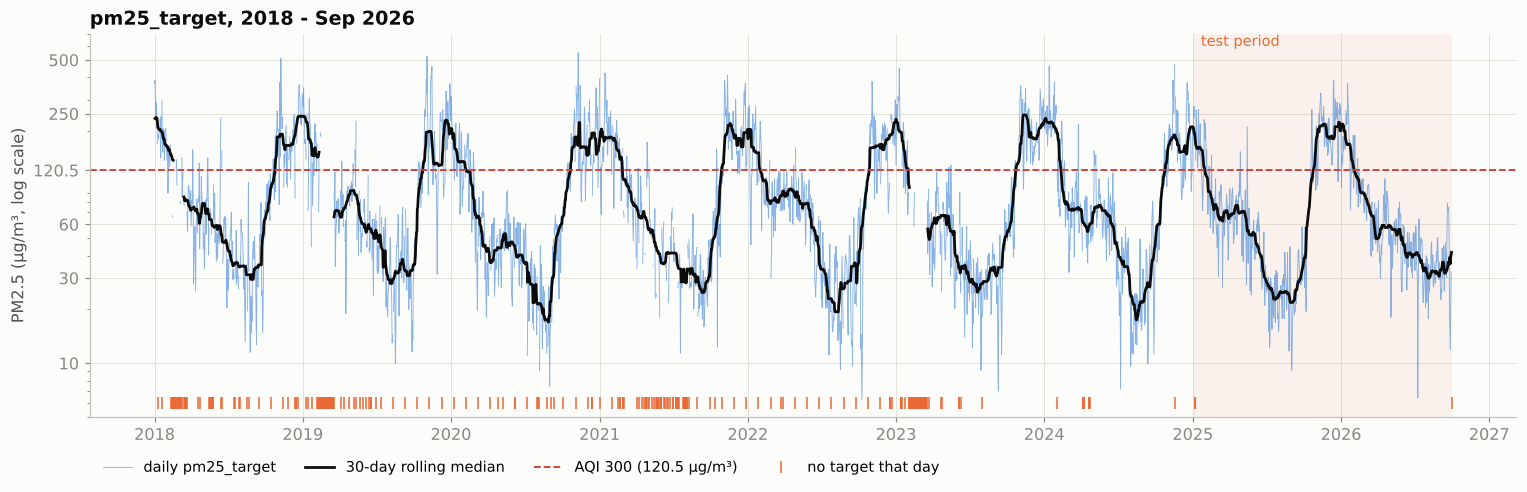

In [8]:
s = df.set_index("date")[PM]
log_s = np.log(s)
train_log = log_s[:TRAIN_END]
train_log_i = train_log.interpolate(limit_area="inside")       # analysis copy only
n_interp = int(train_log.isna().sum())
print(f"Training days: {len(train_log)}; {n_interp} interpolated in the analysis copy only "
      f"({100*n_interp/len(train_log):.1f}%).")

fig, ax = plt.subplots(figsize=(14, 4.6))
ax.axvspan(TEST_START, TEST_END, color=ORANGE, alpha=0.07, lw=0)
ax.plot(s.index, s.values, color=BLUE, lw=0.6, alpha=0.55, label="daily pm25_target")
ax.plot(s.index, s.rolling(30, center=True, min_periods=15).median(), color=INK, lw=1.8, label="30-day rolling median")
ax.axhline(THRESH, color=RED, lw=1.2, ls="--", label="AQI 300 (120.5 µg/m³)")
mdays = s.index[s.isna()]
ax.plot(mdays, np.full(len(mdays), 6), "|", color=ORANGE, ms=8, label="no target that day")
ax.set_yscale("log"); ax.set_ylim(5, 700)
ax.set_yticks([10, 30, 60, 120.5, 250, 500]); ax.set_yticklabels(["10", "30", "60", "120.5", "250", "500"])
ax.text(TEST_START + pd.Timedelta(days=20), 600, "test period", color=ORANGE, fontsize=9.5)
ax.set_ylabel("PM2.5 (µg/m³, log scale)"); ax.set_title("pm25_target, 2018 - Sep 2026")
year_axis(ax); ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=4)
fig.tight_layout(); save(fig, "M2_05_full_series")

### 3.1 Yearly and weekly patterns

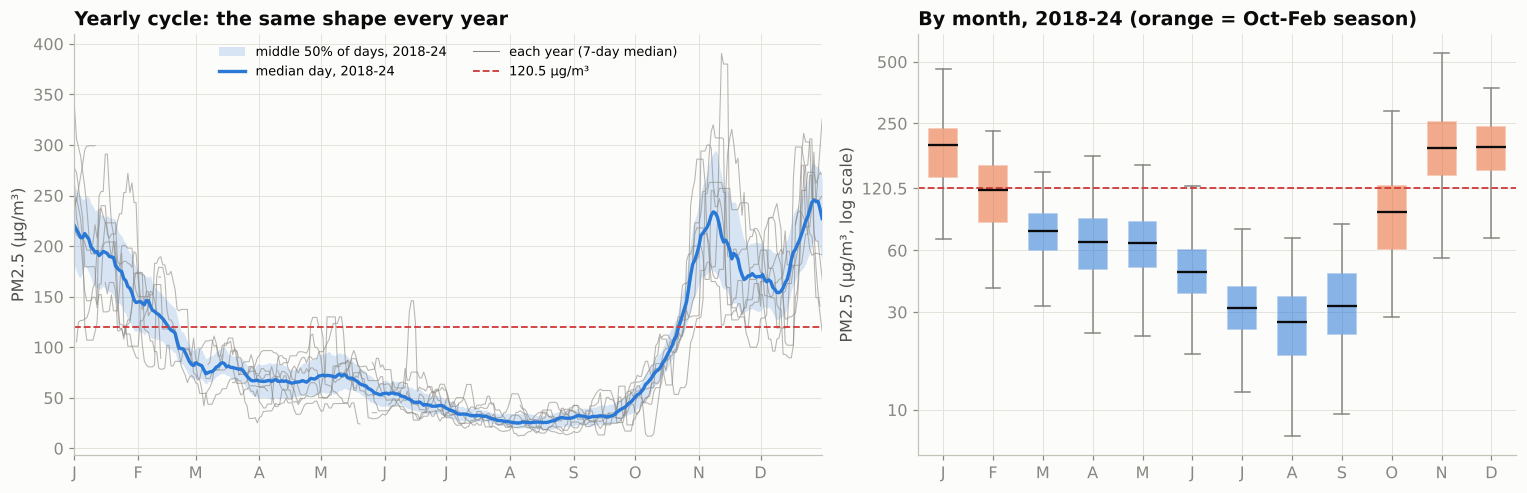

Monthly median, 2018-24: highest Jan (196 µg/m³), lowest Aug (27 µg/m³), a 7.3x swing.
Months whose median day is above 120.5: Jan, Nov, Dec. Share of high-risk days by month (%): {'Jan': 84, 'Feb': 48, 'Mar': 3, 'Apr': 5, 'May': 6, 'Jun': 2, 'Jul': 0, 'Aug': 0, 'Sep': 0, 'Oct': 26, 'Nov': 84, 'Dec': 85}


In [9]:
tr = s[:TRAIN_END].dropna()
doy = tr.index.dayofyear.where(~(tr.index.is_leap_year & (tr.index.dayofyear > 59)), tr.index.dayofyear - 1)
prof = tr.groupby(doy).quantile([.25, .5, .75]).unstack()
circ = lambda x: pd.concat([x.iloc[-15:], x, x.iloc[:15]]).rolling(15, center=True).mean().iloc[15:-15]
prof = prof.apply(circ)
month_start = pd.date_range("2023-01-01", periods=12, freq="MS").dayofyear

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
for y in range(2018, 2025):
    sy = s[str(y)]
    ax.plot(sy.index.dayofyear, sy.rolling(7, min_periods=4, center=True).median(), color=MUTED, lw=0.7, alpha=0.6)
ax.fill_between(prof.index, prof[.25], prof[.75], color=BLUE, alpha=0.18, lw=0, label="middle 50% of days, 2018-24")
ax.plot(prof.index, prof[.5], color=BLUE, lw=2.2, label="median day, 2018-24")
ax.plot([], [], color=MUTED, lw=0.7, label="each year (7-day median)")
ax.axhline(THRESH, color=RED, ls="--", lw=1.2, label="120.5 µg/m³")
ax.set_xticks(month_start); ax.set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"])
ax.set_xlim(1, 365); ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_title("Yearly cycle: the same shape every year")
ax.legend(loc="upper center", fontsize=8.5, ncol=2)

ax = axes[1]
monthly = [np.log(tr[tr.index.month == m]) for m in range(1, 13)]
bp = ax.boxplot(monthly, patch_artist=True, widths=0.6, showfliers=False,
                medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for patch, m in zip(bp["boxes"], range(1, 13)):
    patch.set_facecolor(ORANGE if m in SEASON else BLUE); patch.set_alpha(0.55); patch.set_edgecolor(SURFACE)
ax.axhline(np.log(THRESH), color=RED, ls="--", lw=1.2)
ax.set_yticks(np.log([10, 30, 60, 120.5, 250, 500])); ax.set_yticklabels(["10", "30", "60", "120.5", "250", "500"])
ax.set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"])
ax.set_title("By month, 2018-24 (orange = Oct-Feb season)"); ax.set_ylabel("PM2.5 (µg/m³, log scale)")
fig.tight_layout(); save(fig, "M2_06_yearly_pattern")

mm = tr.groupby(tr.index.month).median()
above = [MNAME[m] for m in mm.index if mm[m] >= THRESH]
hr_m = df[df.date <= TRAIN_END].groupby(df.date.dt.month).high_risk.mean().mul(100).round(0)
print(f"Monthly median, 2018-24: highest {MNAME[mm.idxmax()]} ({mm.max():.0f} µg/m³), lowest {MNAME[mm.idxmin()]} "
      f"({mm.min():.0f} µg/m³), a {mm.max()/mm.min():.1f}x swing.")
print(f"Months whose median day is above 120.5: {', '.join(above)}. Share of high-risk days by month (%): "
      f"{ {MNAME[k]: int(v) for k, v in hr_m.items()} }")

**Weekly pattern.** To test for a weekday effect without the yearly cycle getting in the way, the weekday comparison is done on the **deseasonalised** log series (log PM2.5 minus the smooth yearly cycle fitted in §3.3). A Kruskal–Wallis test checks whether any weekday differs.

K,1,2,3,4,5,6,7,8,9,10,11,12
params,3.0000,5.0000,7.0000,9.0000,11.0000,13.0000,15.0000,17.0000,19.0000,21.0000,23.0000,25.0000
"validation MAE (log, 2023-24)",0.4178,0.3330,0.3323,0.3225,0.3169,0.3151,0.3156,0.3167,0.3160,0.3160,0.3174,0.3208
R2 (2018-24),0.5919,0.7150,0.7191,0.7300,0.7356,0.7425,0.7436,0.7462,0.7469,0.7474,0.7477,0.7477
BIC (2018-24),-2904.9347,-3710.7942,-3729.1581,-3804.0951,-3836.2483,-3881.2824,-3875.7491,-3883.2131,-3874.8213,-3863.5986,-3850.7173,-3835.5357


Chosen K = 6 harmonic pairs (lowest validation error on 2023-24; BIC's choice, K = 8, is within 2 BIC points). The smooth yearly cycle alone explains 74% of the variance of log PM2.5 in 2018-24.


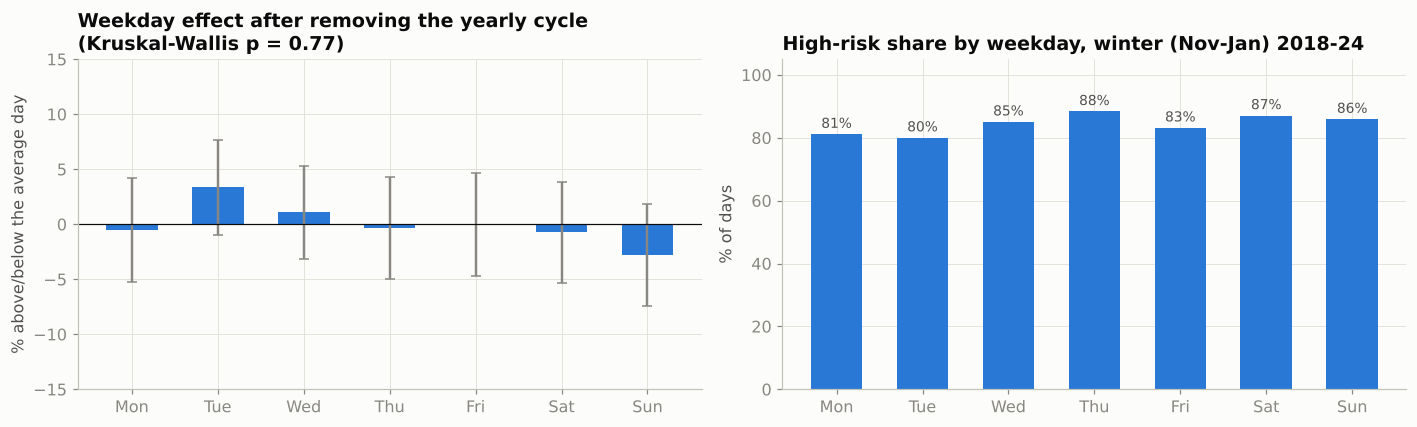

Largest weekday effect: 3.3%; Kruskal-Wallis p = 0.77. No weekly seasonality -> no weekly terms needed, and a lag-7 seasonal naive would be meaningless.


In [10]:
# Smooth yearly cycle: Fourier (harmonic) regression on log PM2.5, training data only. K chosen by BIC.
def fourier(dates, K, period=365.25):
    t = np.asarray(dates.dayofyear, dtype=float)
    cols = {}
    for k in range(1, K + 1):
        cols[f"sin{k}"] = np.sin(2 * np.pi * k * t / period)
        cols[f"cos{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(cols, index=dates)

# K is chosen by time-ordered validation: fit on 2018-22, score on 2023-24 (log MAE). BIC on 2018-24 shown alongside.
def design(dates, K):
    return np.column_stack([np.ones(len(dates)), fourier(dates, K).values])

y_tr = train_log.dropna()
y_fit, y_val = y_tr[:"2022-12-31"], y_tr["2023-01-01":]
fits = []
for K in range(1, 13):
    b_fit, *_ = np.linalg.lstsq(design(y_fit.index, K), y_fit.values, rcond=None)
    val_mae = np.mean(np.abs(design(y_val.index, K) @ b_fit - y_val.values))
    X = design(y_tr.index, K)
    beta, *_ = np.linalg.lstsq(X, y_tr.values, rcond=None)
    rss = ((y_tr.values - X @ beta) ** 2).sum(); n, p = len(y_tr), X.shape[1]
    fits.append({"K": K, "params": p, "validation MAE (log, 2023-24)": val_mae,
                 "R2 (2018-24)": 1 - rss / ((y_tr - y_tr.mean()) ** 2).sum(),
                 "BIC (2018-24)": n * np.log(rss / n) + p * np.log(n), "beta": beta})
kt = pd.DataFrame(fits).set_index("K")
K_BEST = int(kt["validation MAE (log, 2023-24)"].idxmin())
BETA = kt.loc[K_BEST, "beta"]                     # refitted on all of 2018-24
display(kt.drop(columns="beta").round(4).T)
print(f"Chosen K = {K_BEST} harmonic pairs (lowest validation error on 2023-24; BIC's choice, "
      f"K = {int(kt['BIC (2018-24)'].idxmin())}, is within {abs(kt['BIC (2018-24)'].min() - kt.loc[K_BEST,'BIC (2018-24)']):.0f} BIC points). "
      f"The smooth yearly cycle alone explains {100*kt.loc[K_BEST,'R2 (2018-24)']:.0f}% of the variance of log PM2.5 in 2018-24.")

def seasonal_fit(dates):
    return pd.Series(design(dates, K_BEST) @ BETA, index=dates)

season_all = seasonal_fit(log_s.index)
deseason = log_s - season_all                        # with gaps
deseason_tr_i = (train_log_i - season_all[:TRAIN_END])   # analysis copy, gaps interpolated

# Weekday effect on the deseasonalised training series
dz = deseason[:TRAIN_END].dropna()
dow = dz.groupby(dz.index.dayofweek)
eff = pd.DataFrame({"effect_%": 100 * (np.exp(dow.mean() - dz.mean()) - 1),
                    "ci_%": 100 * 1.96 * dow.std() / np.sqrt(dow.size())})
kw = stats.kruskal(*[g.values for _, g in dow])
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wint = df[df.date.dt.month.isin(WINTER) & (df.date <= TRAIN_END)].dropna(subset=["high_risk"])
hr_dow = wint.groupby(wint.date.dt.dayofweek).high_risk.mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.bar(names, eff["effect_%"], color=BLUE, width=0.6, yerr=eff["ci_%"], ecolor=MUTED, capsize=3)
ax.axhline(0, color=INK, lw=0.8)
ax.set_title(f"Weekday effect after removing the yearly cycle\n(Kruskal-Wallis p = {kw.pvalue:.2f})")
ax.set_ylabel("% above/below the average day"); ax.set_ylim(-15, 15)
ax = axes[1]
ax.bar(names, hr_dow.values, color=BLUE, width=0.6)
for i, v in enumerate(hr_dow.values):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_title("High-risk share by weekday, winter (Nov-Jan) 2018-24"); ax.set_ylabel("% of days"); ax.set_ylim(0, 105)
fig.tight_layout(); save(fig, "M2_07_weekly_pattern")
print(f"Largest weekday effect: {eff['effect_%'].abs().max():.1f}%; Kruskal-Wallis p = {kw.pvalue:.2f}. "
      f"No weekly seasonality -> no weekly terms needed, and a lag-7 seasonal naive would be meaningless.")

### 3.2 Log-transform check

Two questions: is the distribution very skewed, and does the spread grow with the level (which breaks the constant-variance assumption of ARIMA-type models)?

,skewness,"corr(monthly mean, monthly SD)",highest / lowest monthly SD
raw PM2.5,1.53,0.98,7.20
log PM2.5,-0.06,-0.15,1.63


Box-Cox lambda on 2018-24 = 0.031 (lambda = 0 is exactly the log).


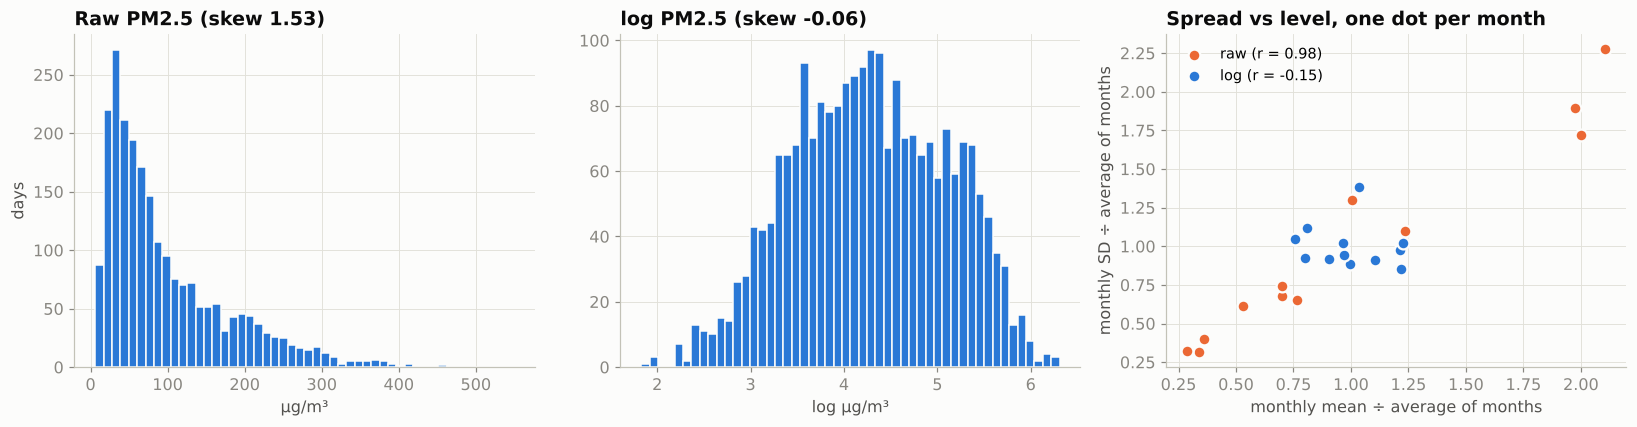

Decision: model log PM2.5. The log removes the skew, and the spread no longer rises with the level. Forecasts are converted back with exp() (this gives the median, which is what MAE rewards).


In [11]:
tr_pos = s[:TRAIN_END].dropna()
bc_lambda = stats.boxcox(tr_pos.values)[1]
mon = pd.DataFrame({"raw_mean": tr_pos.groupby(tr_pos.index.month).mean(),
                    "raw_sd": tr_pos.groupby(tr_pos.index.month).std(),
                    "log_mean": np.log(tr_pos).groupby(tr_pos.index.month).mean(),
                    "log_sd": np.log(tr_pos).groupby(tr_pos.index.month).std()})
r_raw = mon.raw_mean.corr(mon.raw_sd); r_log = mon.log_mean.corr(mon.log_sd)
logtab = pd.DataFrame({
    "skewness": [tr_pos.skew(), np.log(tr_pos).skew()],
    "corr(monthly mean, monthly SD)": [r_raw, r_log],
    "highest / lowest monthly SD": [mon.raw_sd.max() / mon.raw_sd.min(), mon.log_sd.max() / mon.log_sd.min()],
}, index=["raw PM2.5", "log PM2.5"]).round(2)
display(logtab)
print(f"Box-Cox lambda on 2018-24 = {bc_lambda:.3f} (lambda = 0 is exactly the log).")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(tr_pos, bins=50, color=BLUE, edgecolor=SURFACE)
axes[0].set_title(f"Raw PM2.5 (skew {tr_pos.skew():.2f})"); axes[0].set_xlabel("µg/m³"); axes[0].set_ylabel("days")
axes[1].hist(np.log(tr_pos), bins=50, color=BLUE, edgecolor=SURFACE)
axes[1].set_title(f"log PM2.5 (skew {np.log(tr_pos).skew():.2f})"); axes[1].set_xlabel("log µg/m³")
ax = axes[2]
ax.scatter(mon.raw_mean / mon.raw_mean.mean(), mon.raw_sd / mon.raw_sd.mean(), s=60, color=ORANGE,
           edgecolor=SURFACE, lw=1.5, label=f"raw (r = {r_raw:.2f})", zorder=3)
ax.scatter(mon.log_mean / mon.log_mean.mean(), mon.log_sd / mon.log_sd.mean(), s=60, color=BLUE,
           edgecolor=SURFACE, lw=1.5, label=f"log (r = {r_log:.2f})", zorder=3)
ax.set_xlabel("monthly mean ÷ average of months"); ax.set_ylabel("monthly SD ÷ average of months")
ax.set_title("Spread vs level, one dot per month"); ax.legend(loc="upper left")
fig.tight_layout(); save(fig, "M2_08_log_transform_check")
print("Decision: model log PM2.5. The log removes the skew, and the spread no longer rises with the level. "
      "Forecasts are converted back with exp() (this gives the median, which is what MAE rewards).")

### 3.3 STL decomposition

STL on log PM2.5, 2018–2024, with a 365-day period and robust fitting (so pollution spikes like Diwali do not bend the seasonal shape). The smooth Fourier cycle from above is drawn on the seasonal panel for comparison. With only seven years, STL's seasonal line carries day-to-day noise; the Fourier curve is the version recommended for modelling.

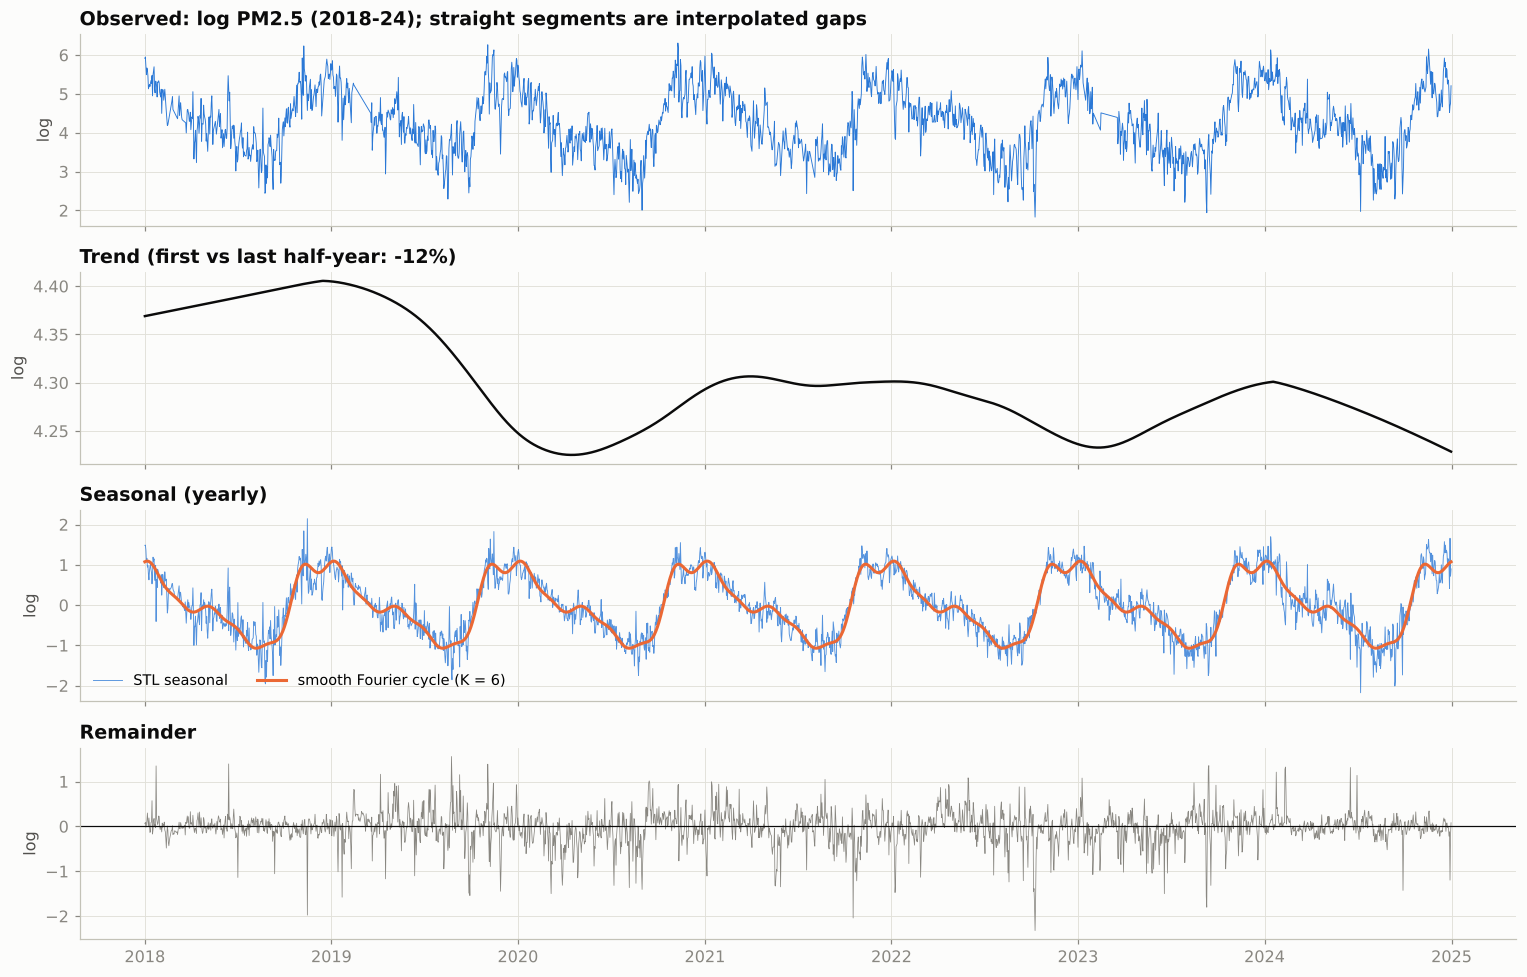

Seasonal strength F_s = 0.80 (strong; 1 = all seasonal), trend strength F_t = 0.05 (weak).
Seasonal swing by month: Nov is 7.5x the level of Aug.
Remainder SD = 0.36 in log units (about ±43% day to day around trend + season).


In [12]:
stl = STL(train_log_i, period=365, robust=True).fit()
T, S_, R = stl.trend, stl.seasonal, stl.resid
F_s = max(0, 1 - R.var() / (S_ + R).var())
F_t = max(0, 1 - R.var() / (T + R).var())
trend_change = 100 * (np.exp(T.iloc[-183:].mean() - T.iloc[:183].mean()) - 1)

fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
axes[0].plot(train_log_i.index, train_log_i, color=BLUE, lw=0.6); axes[0].set_title("Observed: log PM2.5 (2018-24); straight segments are interpolated gaps")
axes[1].plot(T.index, T, color=INK, lw=1.6); axes[1].set_title(f"Trend (first vs last half-year: {trend_change:+.0f}%)")
axes[2].plot(S_.index, S_, color=BLUE, lw=0.6, alpha=0.8, label="STL seasonal")
axes[2].plot(S_.index, season_all[:TRAIN_END] - season_all[:TRAIN_END].mean(), color=ORANGE, lw=2,
             label=f"smooth Fourier cycle (K = {K_BEST})")
axes[2].set_title("Seasonal (yearly)"); axes[2].legend(loc="lower left", ncol=2)
axes[3].plot(R.index, R, color=MUTED, lw=0.5); axes[3].axhline(0, color=INK, lw=0.8); axes[3].set_title("Remainder")
for a in axes: a.set_ylabel("log")
year_axis(axes[3]); fig.tight_layout(); save(fig, "M2_09_stl_decomposition")

sm = S_.groupby(S_.index.month).mean()
print(f"Seasonal strength F_s = {F_s:.2f} (strong; 1 = all seasonal), trend strength F_t = {F_t:.2f} (weak).")
print(f"Seasonal swing by month: {MNAME[sm.idxmax()]} is {np.exp(sm.max()-sm.min()):.1f}x the level of {MNAME[sm.idxmin()]}.")
print(f"Remainder SD = {R.std():.2f} in log units (about ±{100*(np.exp(R.std())-1):.0f}% day to day around trend + season).")

### 3.4 Stationarity tests

ADF and KPSS ask opposite questions, so they are read together:

* **ADF** — null hypothesis: the series has a unit root (not stationary). Small p → stationary.
* **KPSS** — null hypothesis: the series is stationary. Small p → not stationary.

Three versions of the 2018–24 log series are tested: as it is, with the smooth yearly cycle removed, and first-differenced.

In [13]:
def adf_kpss(x, name):
    x = x.dropna()
    a = adfuller(x, autolag="AIC")
    k = kpss(x, regression="c", nlags="auto")
    adf_ok, kpss_ok = a[1] < 0.05, k[1] > 0.05
    verdict = {(True, True): "stationary (both agree)",
               (False, False): "not stationary (both agree)",
               (True, False): "ADF: no unit root, KPSS: level not constant",
               (False, True): "unclear (ADF cannot reject unit root)"}[(adf_ok, kpss_ok)]
    return {"series": name, "ADF stat": round(a[0], 2), "ADF p": round(a[1], 4), "ADF lags": a[2],
            "KPSS stat": round(k[0], 3), "KPSS p": (">0.10" if k[1] >= 0.1 else ("<0.01" if k[1] <= 0.01 else round(k[1], 3))),
            "verdict": verdict}

st_tab = pd.DataFrame([adf_kpss(train_log_i, "log PM2.5"),
                       adf_kpss(deseason_tr_i, f"log PM2.5 minus yearly cycle (K={K_BEST})"),
                       adf_kpss(train_log_i.diff(), "first difference of log PM2.5")])
st_tab.to_csv(OUT / "p2_stationarity_tests.csv", index=False)
display(st_tab)

# Is the deseasonalised level stable from year to year? (explains any KPSS rejection)
yr_lvl = deseason[:TRAIN_END].groupby(deseason[:TRAIN_END].index.year).mean()
yl = (np.exp(yr_lvl - yr_lvl.mean()) - 1).mul(100).round(0)
print("Level of each year after removing the yearly cycle (% vs the 2018-24 average):", yl.astype(int).to_dict())

,series,ADF stat,ADF p,ADF lags,KPSS stat,KPSS p,verdict
0,log PM2.5,-3.85,0.0024,14,0.075,>0.10,stationary (both agree)
1,log PM2.5 minus yearly cycle (K=6),-14.68,0.0000,5,0.581,0.024,"ADF: no unit root, KPSS: level not constant"
2,first difference of log PM2.5,-18.92,0.0000,13,0.066,>0.10,stationary (both agree)


Level of each year after removing the yearly cycle (% vs the 2018-24 average): {2018: 12, 2019: 8, 2020: -11, 2021: 1, 2022: -3, 2023: -5, 2024: 1}


**Reading the tests.**
* ADF rejects a unit root in every version, so the series does **not** wander like a random walk: after a bad spell it returns to its seasonal level. **No differencing is needed** (d = 0); differencing would only throw away the level information that the alert depends on.
* The raw log series passes both tests because it repeats the same yearly cycle; that cycle is deterministic (same calendar every year), so it is handled with the Fourier terms rather than by seasonal differencing.
* After removing the cycle, KPSS objects that the level is not perfectly constant. The year-level line above shows why: some years sit higher or lower than others (2020, the lockdown year, is the lowest). These are shifts of about ±10%, not a trend. An AR term absorbs them in practice; a slowly-moving level term is optional for M3.

### 3.5 ACF and PACF

Top: the autocorrelation of log PM2.5 over 400 days shows the yearly cycle (negative at about half a year, positive again near 365). Bottom: after removing the yearly cycle, the ACF and PACF show how many past days actually carry information.

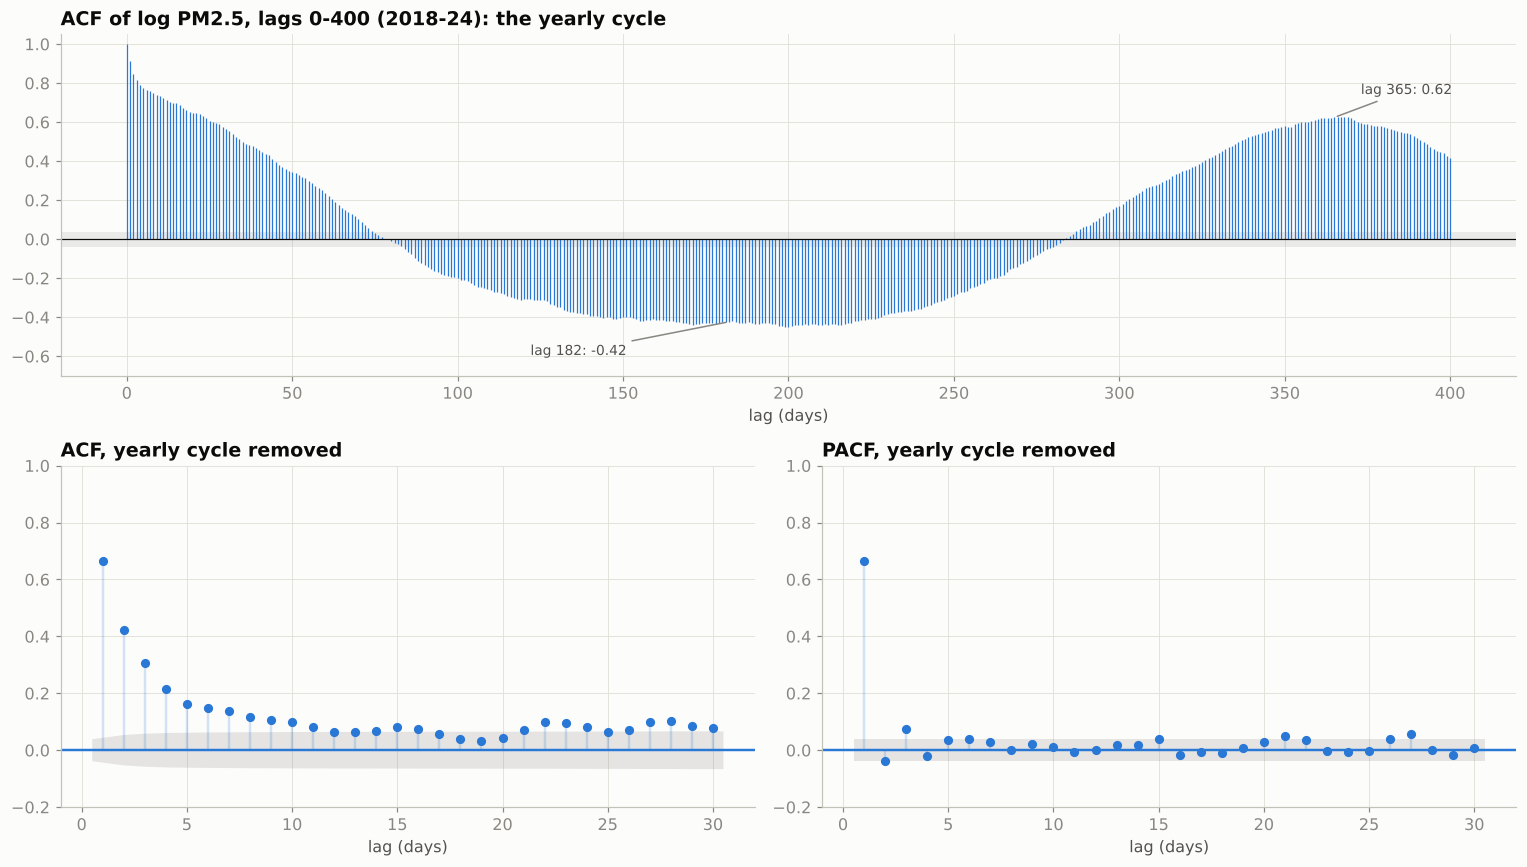

ACF of log level: lag 1 = 0.91, lag 7 = 0.76, lag 30 = 0.56, lag 182 = -0.42, lag 365 = 0.62
After removing the yearly cycle: ACF lag 1 = 0.67, lag 3 = 0.31, lag 7 = 0.14; PACF lag 1 = 0.67, lag 2 = -0.04, lag 3 = 0.07.
PACF lags outside ±0.039: [1, 3, 21, 27] (all except lag 1 are below 0.07)


In [14]:
ac_lvl = acf(train_log_i, nlags=400, fft=True)
ac_des = acf(deseason_tr_i, nlags=30, fft=True)
pc_des = pacf(deseason_tr_i, nlags=30, method="ywm")
conf = 1.96 / np.sqrt(len(deseason_tr_i))
sig_pacf = [k for k in range(1, 31) if abs(pc_des[k]) > conf]

fig = plt.figure(figsize=(14, 8))
ax0 = fig.add_subplot(2, 1, 1)
ax0.vlines(range(len(ac_lvl)), 0, ac_lvl, color=BLUE, lw=0.8)
ax0.axhline(0, color=INK, lw=0.8); ax0.axhspan(-conf, conf, color=MUTED, alpha=0.15, lw=0)
for lag in [182, 365]:
    ax0.annotate(f"lag {lag}: {ac_lvl[lag]:.2f}", (lag, ac_lvl[lag]), xytext=((lag + 8, ac_lvl[lag] + 0.12) if lag == 365 else (lag - 60, ac_lvl[lag] - 0.17)),
                 fontsize=9, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax0.set_title("ACF of log PM2.5, lags 0-400 (2018-24): the yearly cycle"); ax0.set_xlabel("lag (days)"); ax0.set_ylim(-0.7, 1.05)
ax1 = fig.add_subplot(2, 2, 3)
plot_acf(deseason_tr_i, lags=30, ax=ax1, color=BLUE, vlines_kwargs={"colors": BLUE}, zero=False)
ax1.set_title("ACF, yearly cycle removed"); ax1.set_xlabel("lag (days)"); ax1.set_ylim(-0.2, 1)
ax2 = fig.add_subplot(2, 2, 4)
plot_pacf(deseason_tr_i, lags=30, ax=ax2, color=BLUE, vlines_kwargs={"colors": BLUE}, zero=False, method="ywm")
ax2.set_title("PACF, yearly cycle removed"); ax2.set_xlabel("lag (days)"); ax2.set_ylim(-0.2, 1)
for a in (ax1, ax2):
    for coll in a.collections: coll.set_facecolor(MUTED); coll.set_alpha(0.2)
fig.tight_layout(); save(fig, "M2_10_acf_pacf")

print(f"ACF of log level: lag 1 = {ac_lvl[1]:.2f}, lag 7 = {ac_lvl[7]:.2f}, lag 30 = {ac_lvl[30]:.2f}, "
      f"lag 182 = {ac_lvl[182]:.2f}, lag 365 = {ac_lvl[365]:.2f}")
print(f"After removing the yearly cycle: ACF lag 1 = {ac_des[1]:.2f}, lag 3 = {ac_des[3]:.2f}, lag 7 = {ac_des[7]:.2f}; "
      f"PACF lag 1 = {pc_des[1]:.2f}, lag 2 = {pc_des[2]:.2f}, lag 3 = {pc_des[3]:.2f}.")
print(f"PACF lags outside ±{conf:.3f}: {sig_pacf} (all except lag 1 are below {max(abs(pc_des[k]) for k in sig_pacf if k > 1):.2f})")

**Reading the ACF and PACF.** With the yearly cycle in, today's value is correlated with values months back — but only because both sit in the same season. Once the cycle is removed, the ACF decays smoothly (lag 1, 2, 3 printed above) and the PACF has one large spike at lag 1 and only tiny ones after it. That is the signature of an **AR(1)** process: yesterday's deviation from the seasonal normal carries the information, and earlier days add very little once yesterday is known. It also explains why persistence is hard to beat at day 1 and why its edge fades by days 2–3: the correlation with the origin day falls quickly with the gap.

In [15]:
# Add the chosen Fourier terms to the inputs file (deterministic from the date, so safe for any horizon)
fz = fourier(pd.DatetimeIndex(ts.date), K_BEST).reset_index(drop=True)
ts = pd.concat([ts, fz.add_prefix("fourier_")], axis=1)
ts["yearly_cycle_log"] = season_all.values

handoff = pd.DataFrame([
    ("Transform", f"Model log PM2.5 (Box-Cox λ = {bc_lambda:.2f} ≈ 0). Back-transform with exp() (gives the median).",
     "§3.2"),
    ("Yearly seasonality", f"Strong (F_s = {F_s:.2f}). Use {K_BEST} Fourier pairs as exogenous terms (columns fourier_* in "
     "p2_ts_inputs.csv), not a 365-period SARIMA, which is impractical with daily data and only 7 years.", "§3.3"),
    ("Weekly seasonality", f"None (largest weekday effect {eff['effect_%'].abs().max():.1f}%, p = {kw.pvalue:.2f}). "
     "No weekly terms.", "§3.1"),
    ("Differencing", "d = 0. ADF rejects a unit root in every version; the remaining non-constancy is year-to-year "
     f"level shifts (largest {yl.abs().max():.0f}%), not a random walk.", "§3.4"),
    ("AR order", f"AR(1) on the deseasonalised log series: PACF lag 1 = {pc_des[1]:.2f}, every other lag within "
     f"±{max(abs(pc_des[k]) for k in range(2, 31)):.2f}. Test AR(2)/AR(3) as a check; MA terms are not indicated.", "§3.5"),
    ("Inputs", "Lags from pm25_target only (pm25_input_lag1-7). Weather enters lagged for days 2-3, or is labelled "
     "as a perfect forecast.", "§1, §2"),
    ("Benchmark to beat", "Persistence for days 1-3 and the day-of-year average, scored on the same days (p2_baselines.csv).",
     "§4"),
], columns=["Topic", "Recommendation for M3", "Evidence"])
display(handoff)

,Topic,Recommendation for M3,Evidence
0,Transform,Model log PM2.5 (Box-Cox λ = 0.03 ≈ 0). Back-transform with exp() (gives the median).,§3.2
1,Yearly seasonality,"Strong (F_s = 0.80). Use 6 Fourier pairs as exogenous terms (columns fourier_* in p2_ts_inputs.csv), not a 365-period SARIMA, which is i...",§3.3
2,Weekly seasonality,"None (largest weekday effect 3.3%, p = 0.77). No weekly terms.",§3.1
3,Differencing,"d = 0. ADF rejects a unit root in every version; the remaining non-constancy is year-to-year level shifts (largest 12%), not a random walk.",§3.4
4,AR order,"AR(1) on the deseasonalised log series: PACF lag 1 = 0.67, every other lag within ±0.07. Test AR(2)/AR(3) as a check; MA terms are not i...",§3.5
5,Inputs,"Lags from pm25_target only (pm25_input_lag1-7). Weather enters lagged for days 2-3, or is labelled as a perfect forecast.","§1, §2"
6,Benchmark to beat,"Persistence for days 1-3 and the day-of-year average, scored on the same days (p2_baselines.csv).",§4


## 4. Task 4 — Baselines for days 1, 2 and 3

A forecast is issued at the end of day *t* (the origin) for day *t + h*, h = 1, 2, 3.

| Baseline | Forecast for day *t + h* | Uses recent data? |
|---|---|---|
| **Persistence** | the value on the origin day *t* (`pm25_input`, i.e. carried forward at most 2 days if *t* itself is missing) | yes, so it gets worse with *h* |
| **Seasonal naive** | the value on the same calendar date one year earlier (29 Feb → 28 Feb) | no, so it is identical for every *h* |
| **Day-of-year average** | the median of log PM2.5 for that day of the year over **2018–2024**, smoothed over 15 days, back-transformed | no, identical for every *h* |

A weekly (lag-7) seasonal naive is not used: §3.1 showed there is no weekly cycle. The day-of-year average is added because last year's single value is noisy; it is the fairer "what the season alone tells you" benchmark.

**Scoring rules.** Only days with a real observed target are scored. To make every number comparable, all baselines and horizons are scored on one **common set** of test days where every baseline has a forecast for every horizon. Alert metrics use the same 120.5 cut-off as Phase 1.

In [16]:
inp_s = ts.set_index("date")["pm25_input"]

def doy365(idx):
    d = idx.dayofyear
    return np.where(idx.is_leap_year & (d > 59), d - 1, d)

def climatology_profile(fit_end):
    # Smoothed day-of-year median of log PM2.5 using data up to fit_end only (expanding, never looks ahead)
    x = log_s[:fit_end].dropna()
    med = x.groupby(doy365(x.index)).median().reindex(range(1, 366)).interpolate(limit_direction="both")
    w = CLIM_WINDOW // 2
    wrapped = pd.concat([med.iloc[-w:], med, med.iloc[:w]])
    return np.exp(wrapped.rolling(CLIM_WINDOW, center=True).mean().iloc[w:-w])

def last_year(dates):
    prev = dates - pd.DateOffset(years=1)          # pandas maps 29 Feb -> 28 Feb
    return inp_s.reindex(prev).values

frames = []
for h in HORIZONS:
    tgt = df[["date", PM, "high_risk"]].rename(columns={PM: "actual"}).copy()
    tgt["horizon"] = h
    tgt["origin_date"] = tgt.date - pd.Timedelta(days=h)
    tgt["persistence"] = inp_s.reindex(tgt.origin_date).values
    tgt["seasonal_naive"] = last_year(pd.DatetimeIndex(tgt.date))
    frames.append(tgt)
base = pd.concat(frames, ignore_index=True)
base["period"] = np.where(base.date <= TRAIN_END, "train", "test")

# Day-of-year average: test days use 2018-24; each backtest year Y uses only years before Y
base["climatology"] = np.nan
for yr in range(2019, 2027):
    fit_end = min(pd.Timestamp(f"{yr-1}-12-31"), TRAIN_END)
    prof_y = climatology_profile(fit_end)
    m = base.date.dt.year == yr
    base.loc[m, "climatology"] = prof_y.reindex(doy365(pd.DatetimeIndex(base.loc[m, "date"]))).values

B = list(BASE_COL)
base["eval_common"] = False
ok_rows = base.dropna(subset=["actual"] + B)
ok_dates = ok_rows.groupby("date").horizon.nunique()
common_dates = ok_dates[ok_dates == len(HORIZONS)].index
base.loc[base.date.isin(common_dates), "eval_common"] = True

# Leakage guards
assert (base.origin_date < base.date).all()
chk = base.dropna(subset=["persistence"]).sample(200, random_state=SEED)
for _, r in chk.iterrows():
    v = df.loc[(df.date <= r.origin_date) & (df.date >= r.origin_date - pd.Timedelta(days=FFILL_LIMIT)), [ "date", PM]].dropna()
    assert np.isclose(v.iloc[-1][PM], r.persistence) and v.iloc[-1].date <= r.origin_date

test_common = base[(base.period == "test") & base.eval_common]
print(f"Test target days with an observed value: {base[(base.period=='test') & base.horizon.eq(1)].actual.notna().sum()}; "
      f"common scoring set (every baseline, every horizon): {test_common.date.nunique()} days.")
display(base[base.period == "test"].groupby("horizon")[B].apply(lambda g: g.notna().sum()).rename_axis("horizon"))

Test target days with an observed value: 635; common scoring set (every baseline, every horizon): 632 days.


,persistence,seasonal_naive,climatology
horizon,,,
1,638,635,638
2,638,635,638
3,638,635,638


In [17]:
def scores(g, col):
    y, f = g["actual"].values, g[col].values
    yb, fb = y >= THRESH, f >= THRESH
    tp, fp, fn = int((yb & fb).sum()), int((~yb & fb).sum()), int((yb & ~fb).sum())
    return {"n": len(g), "MAE": np.mean(np.abs(f - y)), "RMSE": np.sqrt(np.mean((f - y) ** 2)),
            "bias": np.mean(f - y), "MAE_log": np.mean(np.abs(np.log(f) - np.log(y))),
            "high_risk_days": int(yb.sum()), "caught": tp, "missed": fn, "false_alarms": fp,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else np.nan}

def block_boot_mae(g, col, n_boot=N_BOOT, block=BLOCK):
    # Moving-block bootstrap over the date-ordered error series: keeps day-to-day correlation
    e = np.abs(g.sort_values("date")[col].values - g.sort_values("date")["actual"].values)
    n = len(e); nb = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, size=(n_boot, nb))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n]
    m = e[idx].mean(axis=1)
    return np.percentile(m, [2.5, 97.5])

prev_actual = df.set_index("date")[PM].shift(1)
segments = {
    "all test days": lambda g: g,
    "winter (Nov-Jan)": lambda g: g[g.date.dt.month.isin(WINTER)],
    "season (Oct-Feb)": lambda g: g[g.date.dt.month.isin(SEASON)],
    "episode starts": lambda g: g[(g.actual >= THRESH) & (prev_actual.reindex(g.date).values < THRESH)],
}
rows = []
for h in HORIZONS:
    gh = test_common[test_common.horizon == h]
    for seg, fsel in segments.items():
        gs = fsel(gh)
        for b in B:
            r = {"baseline": b, "horizon": h, "segment": seg, **scores(gs, b)}
            if seg == "all test days":
                r["MAE_CI_low"], r["MAE_CI_high"] = block_boot_mae(gs, b)
            rows.append(r)
metrics = pd.DataFrame(rows)
metrics.round(4).to_csv(OUT / "p2_baseline_metrics.csv", index=False)

show = (metrics[metrics.segment == "all test days"]
        .assign(**{"MAE 95% CI": lambda m: m.MAE_CI_low.round(1).astype(str) + "-" + m.MAE_CI_high.round(1).astype(str)})
        [["baseline", "horizon", "n", "MAE", "MAE 95% CI", "RMSE", "bias", "recall", "precision", "F1",
          "caught", "missed", "false_alarms"]])
print("ALL TEST DAYS (Jan 2025 - Sep 2026), common scoring set")
display(show.round(3).set_index(["baseline", "horizon"]))
print("WINTER (Nov-Jan) and SEASON (Oct-Feb)")
display(metrics[metrics.segment.isin(["winter (Nov-Jan)", "season (Oct-Feb)"])]
        .pivot_table(index=["baseline", "horizon"], columns="segment", values=["MAE", "RMSE", "recall", "precision"])
        .round(3))
print("EPISODE STARTS (high-risk day after a day below the line): how many does each baseline catch?")
display(metrics[metrics.segment == "episode starts"].pivot_table(index="baseline", columns="horizon",
        values=["n", "caught", "recall"]).round(3))

ALL TEST DAYS (Jan 2025 - Sep 2026), common scoring set


,,n,MAE,MAE 95% CI,RMSE,bias,recall,precision,F1,caught,missed,false_alarms
baseline,horizon,,,,,,,,,,,
persistence,1,632,18.818,14.6-22.8,30.751,0.286,0.875,0.868,0.872,112,16,17
seasonal_naive,1,632,32.412,24.9-39.9,52.949,4.158,0.789,0.759,0.774,101,27,32
climatology,1,632,21.698,16.8-26.2,33.911,1.747,0.938,0.774,0.848,120,8,35
persistence,2,632,24.671,19.0-30.4,40.092,0.442,0.820,0.814,0.817,105,23,24
seasonal_naive,2,632,32.412,25.4-40.3,52.949,4.158,0.789,0.759,0.774,101,27,32
climatology,2,632,21.698,17.0-26.7,33.911,1.747,0.938,0.774,0.848,120,8,35
persistence,3,632,27.539,20.4-33.6,43.604,0.563,0.797,0.791,0.794,102,26,27
seasonal_naive,3,632,32.412,25.0-39.8,52.949,4.158,0.789,0.759,0.774,101,27,32
climatology,3,632,21.698,16.9-26.5,33.911,1.747,0.938,0.774,0.848,120,8,35


WINTER (Nov-Jan) and SEASON (Oct-Feb)


MAE                              RMSE                         precision                            recall                 
segment                season (Oct-Feb) winter (Nov-Jan) season (Oct-Feb) winter (Nov-Jan) season (Oct-Feb) winter (Nov-Jan) season (Oct-Feb) winter (Nov-Jan)
baseline       horizon                                                                                                                                        
climatology    1                 39.376           48.839           53.256           62.686            0.774            0.876            0.952            1.000
               2                 39.376           48.839           53.256           62.686            0.774            0.876            0.952            1.000
               3                 39.376           48.839           53.256           62.686            0.774            0.876            0.952            1.000
persistence    1                 34.161           41.284           47.546           55.823            0.882            0.943            0.889            0.934
               2                 46.507           58.313           62.942           74.826            0.827            0.904            0.833            0.887
               3                 52.195           65.562           68.913           81.722            0.803            0.894            0.810            0.877
seasonal_naive 1                 58.603           78.727           83.780          103.272            0.808            0.881            0.802            0.840
               2                 58.603           78.727           83.780          103.272            0.808            0.881            0.802            0.840
               3                 58.603           78.727           83.780          103.272            0.808            0.881            0.802            0.840

EPISODE STARTS (high-risk day after a day below the line): how many does each baseline catch?


caught                 n             recall              
horizon             1     2     3     1     2     3      1      2      3
baseline                                                                
climatology      12.0  12.0  12.0  16.0  16.0  16.0  0.750  0.750  0.750
persistence       0.0   5.0   7.0  16.0  16.0  16.0  0.000  0.312  0.438
seasonal_naive   11.0  11.0  11.0  16.0  16.0  16.0  0.688  0.688  0.688

In [18]:
# Year-by-year backtest on the training years: the reference M3 needs for time-ordered validation
bt = base[(base.period == "train") & base.date.dt.year.ge(2019)].dropna(subset=["actual"] + B)
bt_rows = []
for (yr, h), g in bt.groupby([bt.date.dt.year, "horizon"]):
    for b in B:
        s_ = scores(g, b); bt_rows.append({"year": yr, "horizon": h, "baseline": b, "n": s_["n"],
                                            "MAE": s_["MAE"], "recall": s_["recall"], "precision": s_["precision"]})
for h in HORIZONS:
    g = test_common[test_common.horizon == h]
    for b in B:
        s_ = scores(g, b); bt_rows.append({"year": "test 2025-26", "horizon": h, "baseline": b, "n": s_["n"],
                                            "MAE": s_["MAE"], "recall": s_["recall"], "precision": s_["precision"]})
backtest = pd.DataFrame(bt_rows)
backtest.round(4).to_csv(OUT / "p2_baseline_backtest.csv", index=False)
print("MAE (µg/m³) by year — each year's day-of-year average is fitted only on the years before it")
display(backtest.pivot_table(index="year", columns=["baseline", "horizon"], values="MAE", sort=False).round(1))

# Reproduce the Phase 1 persistence baseline on its own 635 test rows, as a consistency check
p1_path = find("m4_test.csv", required=False)
if p1_path is not None:
    p1 = pd.read_csv(p1_path, parse_dates=["date"])
    yb, fb = p1.high_risk.astype(bool), p1.prev_high_risk.fillna(0).astype(bool)
    print(f"\nPhase 1 baseline (prev_high_risk) on its {len(p1)} test rows: caught {int((yb&fb).sum())}, "
          f"false alarms {int((~yb&fb).sum())}, missed {int((yb&~fb).sum())}  (Review 1 slide: 111 / 17 / 17)")
    g1 = base[(base.horizon == 1) & base.date.isin(p1.date)].dropna(subset=["persistence"])
    s1 = scores(g1.dropna(subset=["actual"]), "persistence")
    print(f"M2 persistence, day 1, same dates with an input ({s1['n']} rows): caught {s1['caught']}, "
          f"false alarms {s1['false_alarms']}, missed {s1['missed']}")

MAE (µg/m³) by year — each year's day-of-year average is fitted only on the years before it


baseline,persistence,seasonal_naive,climatology,persistence,seasonal_naive,climatology,persistence,seasonal_naive,climatology
horizon,1,1,1,2,2,2,3,3,3
year,,,,,,,,,
2019,28.9,41.6,34.9,39.1,41.9,35.0,44.1,41.8,35.1
2020,23.7,44.4,32.0,33.9,44.4,32.0,36.9,44.4,32.0
2021,27.1,44.7,36.2,37.4,44.5,36.0,40.8,44.7,36.1
2022,22.2,43.2,28.6,29.4,43.2,28.6,32.6,43.2,28.6
2023,22.4,39.7,27.2,29.8,39.8,27.2,31.2,39.7,27.3
2024,25.2,40.7,31.7,31.2,40.8,31.7,34.4,40.7,31.8
test 2025-26,18.8,32.4,21.7,24.7,32.4,21.7,27.5,32.4,21.7



Phase 1 baseline (prev_high_risk) on its 635 test rows: caught 111, false alarms 17, missed 17  (Review 1 slide: 111 / 17 / 17)
M2 persistence, day 1, same dates with an input (635 rows): caught 112, false alarms 17, missed 16


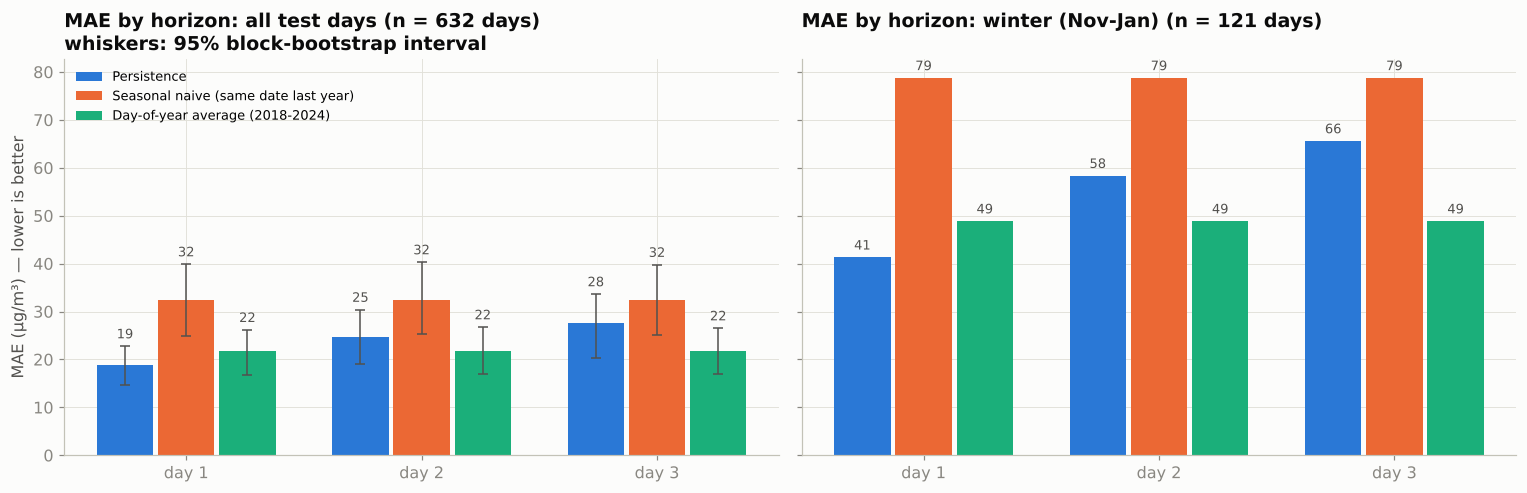

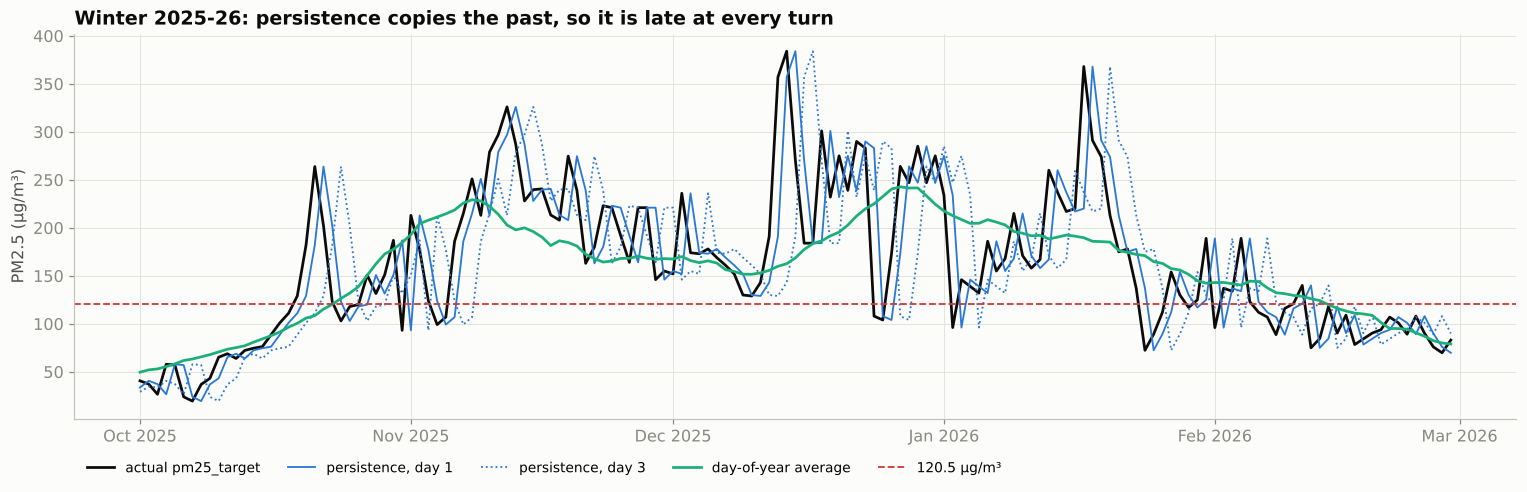

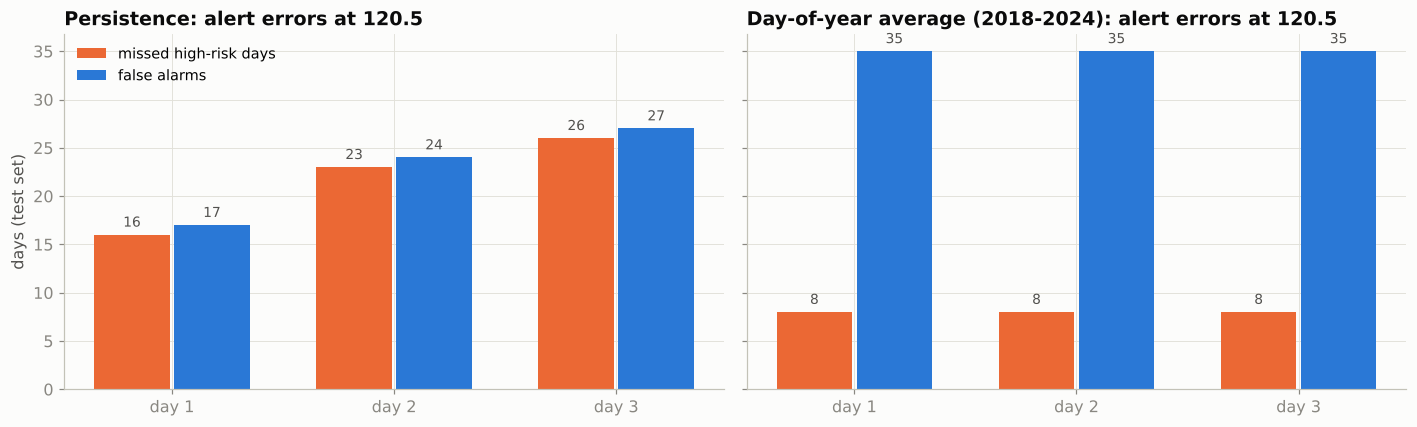

In [19]:
mt = metrics[metrics.segment.isin(["all test days", "winter (Nov-Jan)"])]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, seg in zip(axes, ["all test days", "winter (Nov-Jan)"]):
    g = mt[mt.segment == seg]
    w = 0.26
    for i, b in enumerate(B):
        gb = g[g.baseline == b].set_index("horizon")
        xs = np.array(HORIZONS) + (i - 1) * w
        ax.bar(xs, gb.MAE, width=w - 0.02, color=BASE_COL[b], label=BASE_LBL[b])
        top = gb.MAE_CI_high if seg == "all test days" else gb.MAE
        for xv, v, t_ in zip(xs, gb.MAE, top):
            ax.text(xv, t_ + 1, f"{v:.0f}", ha="center", va="bottom", fontsize=8.5, color=INK2)
        if seg == "all test days":
            ax.errorbar(xs, gb.MAE, yerr=[gb.MAE - gb.MAE_CI_low, gb.MAE_CI_high - gb.MAE], fmt="none",
                        ecolor=INK2, elinewidth=1, capsize=3)
    ax.set_xticks(HORIZONS); ax.set_xticklabels([f"day {h}" for h in HORIZONS])
    ax.set_title(f"MAE by horizon: {seg} (n = {int(g.n.iloc[0])} days)" + ("\nwhiskers: 95% block-bootstrap interval" if seg == "all test days" else "\n"))
axes[0].set_ylabel("MAE (µg/m³) — lower is better"); axes[0].legend(loc="upper left", fontsize=8.5)
fig.tight_layout(); save(fig, "M2_11_baseline_mae_by_horizon")

wz = base[(base.date >= "2025-10-01") & (base.date <= "2026-02-28")]
fig, ax = plt.subplots(figsize=(14, 4.6))
a1 = wz[wz.horizon == 1].set_index("date")
a3 = wz[wz.horizon == 3].set_index("date")
ax.plot(a1.index, a1.actual, color=INK, lw=1.8, label="actual pm25_target")
ax.plot(a1.index, a1.persistence, color=BLUE, lw=1.2, label="persistence, day 1")
ax.plot(a3.index, a3.persistence, color=BLUE, lw=1.2, ls=":", label="persistence, day 3")
ax.plot(a1.index, a1.climatology, color=AQUA, lw=1.8, label="day-of-year average")
ax.axhline(THRESH, color=RED, lw=1.2, ls="--", label="120.5 µg/m³")
ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_title("Winter 2025-26: persistence copies the past, so it is late at every turn")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=5, fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout(); save(fig, "M2_12_winter_2025_26_baselines")

al = metrics[(metrics.segment == "all test days")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, b in zip(axes, ["persistence", "climatology"]):
    g = al[al.baseline == b].set_index("horizon")
    xs = np.array(HORIZONS)
    ax.bar(xs - 0.18, g.missed, width=0.34, color=ORANGE, label="missed high-risk days")
    ax.bar(xs + 0.18, g.false_alarms, width=0.34, color=BLUE, label="false alarms")
    for xv, v in zip(xs - 0.18, g.missed): ax.text(xv, v + 0.5, f"{v}", ha="center", va="bottom", fontsize=9, color=INK2)
    for xv, v in zip(xs + 0.18, g.false_alarms): ax.text(xv, v + 0.5, f"{v}", ha="center", va="bottom", fontsize=9, color=INK2)
    ax.set_xticks(HORIZONS); ax.set_xticklabels([f"day {h}" for h in HORIZONS])
    ax.set_title(f"{BASE_LBL[b]}: alert errors at 120.5")
axes[0].set_ylabel("days (test set)"); axes[0].legend(loc="upper left")
fig.tight_layout(); save(fig, "M2_13_baseline_alert_errors")

In [20]:
a = metrics[metrics.segment == "all test days"].set_index(["baseline", "horizon"])
w = metrics[metrics.segment == "winter (Nov-Jan)"].set_index(["baseline", "horizon"])
es = metrics[metrics.segment == "episode starts"].set_index(["baseline", "horizon"])
best = {h: a.xs(h, level="horizon").MAE.idxmin() for h in HORIZONS}
print("WHAT THE BASELINES SAY")
for h in HORIZONS:
    p = a.loc[("persistence", h)]; c = a.loc[("climatology", h)]; sn = a.loc[("seasonal_naive", h)]
    print(f"Day {h}: persistence MAE {p.MAE:.1f} (CI {p.MAE_CI_low:.1f}-{p.MAE_CI_high:.1f}), recall {p.recall:.2f}, "
          f"precision {p.precision:.2f} | day-of-year avg MAE {c.MAE:.1f} | seasonal naive MAE {sn.MAE:.1f} "
          f"-> best: {BASE_LBL[best[h]]}")
p1, p3 = a.loc[("persistence", 1)], a.loc[("persistence", 3)]
print(f"\nPersistence loses accuracy with lead time: MAE {p1.MAE:.1f} -> {p3.MAE:.1f} µg/m³ "
      f"({100*(p3.MAE/p1.MAE-1):+.0f}%) from day 1 to day 3; alert recall {p1.recall:.2f} -> {p3.recall:.2f}.")
print(f"In winter (Nov-Jan) day-1 persistence MAE is {w.loc[('persistence',1)].MAE:.1f} µg/m³ — the hard season.")
print(f"Episode starts: persistence catches {int(es.loc[('persistence',1)].caught)} of {int(es.loc[('persistence',1)].n)} "
      f"at day 1 (by construction it cannot see a new episode coming); the day-of-year average catches "
      f"{int(es.loc[('climatology',1)].caught)}. This is where M3's models must add value.")
print("Seasonal naive (last year's value) is the weakest everywhere: one noisy year is a poor guide to a specific day.")

# Is the gap between persistence and the day-of-year average real? Paired moving-block bootstrap on the MAE difference.
def paired_diff_ci(g, a_col, b_col, n_boot=N_BOOT, block=BLOCK):
    g = g.sort_values("date")
    d_ = np.abs(g[a_col].values - g.actual.values) - np.abs(g[b_col].values - g.actual.values)
    n = len(d_); nb = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, size=(n_boot, nb))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n]
    return d_.mean(), *np.percentile(d_[idx].mean(axis=1), [2.5, 97.5])

rows = []
for h in HORIZONS:
    for seg in ["all test days", "winter (Nov-Jan)"]:
        g = segments[seg](test_common[test_common.horizon == h])
        m_, lo, hi = paired_diff_ci(g, "persistence", "climatology")
        rows.append({"horizon": h, "segment": seg, "MAE persistence - MAE day-of-year avg": round(m_, 1),
                     "95% CI": f"{lo:.1f} to {hi:.1f}",
                     "reading": "persistence better" if hi < 0 else ("day-of-year avg better" if lo > 0 else "no clear winner")})
paired = pd.DataFrame(rows)
paired.to_csv(OUT / "p2_baseline_paired_difference.csv", index=False)
print("\nPaired difference (negative = persistence has the smaller error):")
display(paired)

share_te = test_common[test_common.horizon == 1].date.dt.month.isin(SEASON).mean()
share_tr = df[(df.date <= TRAIN_END) & df[PM].notna()].date.dt.month.isin(SEASON).mean()
print(f"Note: Oct-Feb days are {100*share_te:.0f}% of the test set but {100*share_tr:.0f}% of the training years "
      f"(2026 stops in September), so test-period MAEs look lower than the yearly backtest. Compare models on the "
      f"same rows, never across periods.")

WHAT THE BASELINES SAY
Day 1: persistence MAE 18.8 (CI 14.6-22.8), recall 0.88, precision 0.87 | day-of-year avg MAE 21.7 | seasonal naive MAE 32.4 -> best: Persistence
Day 2: persistence MAE 24.7 (CI 19.0-30.4), recall 0.82, precision 0.81 | day-of-year avg MAE 21.7 | seasonal naive MAE 32.4 -> best: Day-of-year average (2018-2024)
Day 3: persistence MAE 27.5 (CI 20.4-33.6), recall 0.80, precision 0.79 | day-of-year avg MAE 21.7 | seasonal naive MAE 32.4 -> best: Day-of-year average (2018-2024)

Persistence loses accuracy with lead time: MAE 18.8 -> 27.5 µg/m³ (+46%) from day 1 to day 3; alert recall 0.88 -> 0.80.
In winter (Nov-Jan) day-1 persistence MAE is 41.3 µg/m³ — the hard season.
Episode starts: persistence catches 0 of 16 at day 1 (by construction it cannot see a new episode coming); the day-of-year average catches 12. This is where M3's models must add value.
Seasonal naive (last year's value) is the weakest everywhere: one noisy year is a poor guide to a specific day.

Pair

,horizon,segment,MAE persistence - MAE day-of-year avg,95% CI,reading
0,1,all test days,-2.9,-4.6 to -1.1,persistence better
1,1,winter (Nov-Jan),-7.6,-13.8 to -2.3,persistence better
2,2,all test days,3.0,0.9 to 4.8,day-of-year avg better
3,2,winter (Nov-Jan),9.5,1.7 to 15.7,day-of-year avg better
4,3,all test days,5.8,3.3 to 8.5,day-of-year avg better
5,3,winter (Nov-Jan),16.7,7.4 to 24.3,day-of-year avg better


Note: Oct-Feb days are 33% of the test set but 42% of the training years (2026 stops in September), so test-period MAEs look lower than the yearly backtest. Compare models on the same rows, never across periods.


## 5. Write the outputs and check them against the data contract

In [21]:
series.to_csv(OUT / "p2_series.csv", index=False, date_format="%Y-%m-%d")
ts.to_csv(OUT / "p2_ts_inputs.csv", index=False, date_format="%Y-%m-%d")
cols_out = ["date", "origin_date", "horizon", "period", "actual", "high_risk", "persistence", "seasonal_naive",
            "climatology", "eval_common"]
base[cols_out].sort_values(["horizon", "date"]).to_csv(OUT / "p2_baselines.csv", index=False, date_format="%Y-%m-%d")

# Re-read and check
chk_s = pd.read_csv(OUT / "p2_series.csv", parse_dates=["date"])
assert list(chk_s.columns) == ["date", "pm25_target", "target_source", "missing", "high_risk"]
assert len(chk_s) == n_days and chk_s.date.is_monotonic_increasing and chk_s.date.is_unique
assert chk_s.pm25_target.isna().sum() == chk_s.missing.sum() == n_days - n_known
assert set(chk_s.target_source) == {"reference", "city_fallback", "missing"}
assert ((chk_s.pm25_target >= THRESH) == (chk_s.high_risk == 1))[chk_s.pm25_target.notna()].all()
chk_b = pd.read_csv(OUT / "p2_baselines.csv", parse_dates=["date", "origin_date"])
assert len(chk_b) == n_days * len(HORIZONS)
assert ((chk_b.date - chk_b.origin_date).dt.days == chk_b.horizon).all()

files = ["p2_series.csv", "p2_ts_inputs.csv", "p2_baselines.csv", "p2_baseline_metrics.csv",
         "p2_baseline_backtest.csv", "p2_baseline_paired_difference.csv", "p2_consistency_by_year.csv", "p2_phase1_feature_audit.csv",
         "p2_stationarity_tests.csv"]
summary = pd.DataFrame([{"file": f, "rows": len(pd.read_csv(OUT / f)), "columns": pd.read_csv(OUT / f).shape[1],
                         "KB": round((OUT / f).stat().st_size / 1024)} for f in files])
display(summary)
print("Figures:", sorted(p.name for p in FIG.glob("M2_*.png")))
print("\nAll contract checks passed.")

,file,rows,columns,KB
0,p2_series.csv,3195,5,93
1,p2_ts_inputs.csv,3195,33,1159
2,p2_baselines.csv,9585,10,657
3,p2_baseline_metrics.csv,36,17,4
4,p2_baseline_backtest.csv,63,7,3
5,p2_baseline_paired_difference.csv,6,5,0
6,p2_consistency_by_year.csv,9,10,1
7,p2_phase1_feature_audit.csv,20,8,2
8,p2_stationarity_tests.csv,3,7,0


Figures: ['M2_01_missing_days_by_year.png', 'M2_02_city_mean_vs_target_by_year.png', 'M2_03_high_risk_share_like_for_like.png', 'M2_04_monthly_median_by_year.png', 'M2_05_full_series.png', 'M2_06_yearly_pattern.png', 'M2_07_weekly_pattern.png', 'M2_08_log_transform_check.png', 'M2_09_stl_decomposition.png', 'M2_10_acf_pacf.png', 'M2_11_baseline_mae_by_horizon.png', 'M2_12_winter_2025_26_baselines.png', 'M2_13_baseline_alert_errors.png']

All contract checks passed.


| File | For | Contents |
|---|---|---|
| `p2_series.csv` | everyone (contract) | `date, pm25_target, target_source, missing, high_risk`; 3,195 days, target never filled |
| `p2_ts_inputs.csv` | M3 | `pm25_input` (carried forward ≤ 2 days, past only), `input_age_days`, `input_filled`, log columns, lags 1–7 from the target, calendar fields, `fourier_*` yearly terms, `yearly_cycle_log` |
| `p2_baselines.csv` | M3, M5 | one row per target date × horizon: `origin_date`, `actual`, `high_risk`, the three baselines, `period`, `eval_common` (the shared scoring set) |
| `p2_baseline_metrics.csv` | M3, M1 | MAE (with 95% block-bootstrap CI), RMSE, bias, alert recall/precision/F1, caught/missed/false alarms; all test, winter, season, episode starts |
| `p2_baseline_backtest.csv` | M3 | the same scores per training year 2019–2024, for time-ordered validation |
| `p2_baseline_paired_difference.csv` | M3, M1 | persistence vs day-of-year average, paired bootstrap interval per horizon |
| `p2_consistency_by_year.csv`, `p2_phase1_feature_audit.csv` | M3, M1 | evidence for the consistency check and the Phase 1 leak |
| `p2_stationarity_tests.csv` | M3 | ADF and KPSS results |

## 6. Hand-off notes

**To M3 (models and evaluation)**
1. Read `p2_ts_inputs.csv`; never use `pm25_mean` or its lags. Model log PM2.5 with the `fourier_*` terms, start from AR(1), d = 0 (the modelling table in §3).
2. Score on `eval_common == True` rows of `p2_baselines.csv`, so your numbers and the baselines are on the same days. Report against persistence **and** the day-of-year average.
3. Drop `pm25_mean_change`, `pm10_mean`, `pm25_pm10_ratio`, `pm10_available` from the Phase 1 model and re-score it before any Phase 1 comparison (`p2_phase1_feature_audit.csv`).
4. Episode starts are where persistence fails by construction — report your model's recall on them.

**To M4 (association rules):** use `p2_series.csv` for `high_risk` and for "yesterday's status" (set B). Missing days stay out; don't treat them as 0.

**To M5 (dashboard):** `p2_baselines.csv` gives the persistence line for the forecast chart and the baseline row for the comparison; the 3-day indicator can only show the last date in the data (30 Sep 2026) unless a live pull is built.

**To M1 (report):** the yearly consistency result (2026 is not an anomaly on like-for-like months) and the Phase 1 leak finding both belong in the limitations section.

**Open decision for the team:** this notebook reports both winter definitions (Nov–Jan, Phase 1) and the Oct–Feb season (M4's rule mining). Pick one for the slides.